<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg", align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">Treball Final de Màster</p>
<p style="margin: 0; text-align:right;">MSc in Data Science</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Area 3: Machine Learning in biomarkers and clinical data analytics</p>
<p style="margin: 0; text-align:right; padding-button: 100px;"><strong>Author</strong>: <br>Francesc Ferré Tarrés</p>
<p style="margin: 0; text-align:right; padding-button: 100px;"><strong>Project supervisor</strong>: <br>Clara Gómez Donoso, Laia Subirats Maté </p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>

<br>


# The healthiness and sustainability of food promotions in a Spanish online supermarket

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata # for normalize strings to make joins

# imports de sckikit-learn també falten...

In [2]:
URL_PRODUCT_GROCERY_DATASET = "https://raw.githubusercontent.com/cescFT/TFM-fferretar-code/main/csv/grocery-scraper-results.csv"
URL_AGGREGATION_DATASET = "https://raw.githubusercontent.com/cescFT/TFM-fferretar-code/main/csv/grocery-scraper-aggregation-results.csv"
CL = 0.95
ALPHA = 0.05

# 1. Load datasets

In the following code cells in this section, it checks if the pandas dataframe has been loaded correctly. By using the basic functionalities, such as:
* Function ***read_csv()*** to load datasets correctly in this data analysis environment.
* Function ***head()*** to read the first lines of the file and check data loaded.
* Function ***info()*** to check the aspect of the dataset (number of rows, total columns, name of the columns, non-null for each column, and types of the columns).
* Function ***describe()*** to check the ranges of the values (min, max, IRQ data, std, ...). In case of *object* type columns, this function returns the top value and the frequency of that.

In [3]:
df_products = pd.read_csv(URL_PRODUCT_GROCERY_DATASET, sep="|", parse_dates = [1])
df_aggregation = pd.read_csv(URL_AGGREGATION_DATASET, sep="|", parse_dates = [1])

**Some characteristics and information of the datasets loaded**

This is a brief of the data loaded in this interactive Python notebook. For more information, please visit the associated documentation.

* *df_products*: This dataframe represents the progression of the products week per week. This means a product can appear multiple times if it appears in different weeks in **home page** sections of the online grocery. In addition, the data obtained is from different localities (Can Baró, a neighbourhood in Barcelona, 08032) and Montferri (a village located in the Province of Tarragona, 43812). This can also multiply the number of times the same product appears.
* *df_aggregation*: This dataframe is obtained every week and by postal code. This contains, for each category and subcategory pair, the total number of product items available to be sold. The main reason of the use of this dataframe is to introduce more context in the results.

## 1.1. Describing dataset


### 1.1.1. Dataframe products

In [4]:
df_products.head()

,id,date_scraped,week_num,year,postal_code,ciqual_text_to_search,found_nutriments,origin,id_product,position,...,nutriscore,planetscore,ciqual_text,ciqual_id,ewo_ultra_processed_punctuation,main_page_position,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,1,2026-09-30 11:03:49,40,2026,43812,Pineapple Fruits & vegetables Fruits Tropical ...,1,NaN,3076.0,1,...,NaN,NaN,Pineapple,13002.0,1.0,1,0,1.0,NO_NUTRIMENTS,NaN
1,2,2026-09-30 11:03:51,40,2026,43812,Seedless white grapes Fruits & vegetables Frui...,1,Marruecos,3313.0,2,...,NaN,NaN,"Grape, white, raw",13044.0,1.0,1,0,1.0,NO_NUTRIMENTS,NaN
2,3,2026-09-30 11:03:49,40,2026,43812,"Free range eggs Eggs, milk & butter Eggs Eggs",1,España,15768.0,3,...,NaN,NaN,"Egg, raw",22000.0,2.0,1,0,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,4,2026-09-30 11:03:49,40,2026,43812,Family Whole fresh chicken breast Meat Poultry...,1,España,3682.0,4,...,A,NaN,"Chicken, breast, without skin, raw",36017.0,1.0,1,0,1.0,NaN,NaN
4,5,2026-09-30 11:03:49,40,2026,43812,"Seed mix Hacendado Snacks Nuts, seeds & dried ...",1,Italia,34963.0,5,...,A,NaN,"Mix of nuts and dried fruit, no added salt",15048.0,3.0,1,0,1.0,NaN,NaN


In [5]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1823 entries, 0 to 1822
Data columns (total 36 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id                               1823 non-null   int64         
 1   date_scraped                     1823 non-null   datetime64[ns]
 2   week_num                         1823 non-null   int64         
 3   year                             1823 non-null   int64         
 4   postal_code                      1823 non-null   int64         
 5   ciqual_text_to_search            1823 non-null   object        
 6   found_nutriments                 1823 non-null   int64         
 7   origin                           1746 non-null   object        
 8   id_product                       1823 non-null   float64       
 9   position                         1823 non-null   int64         
 10  category                         1823 non-null   object     

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #1. Brief resume of data loaded of df_products before doing anything</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total variables</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total rows</th>
      <th style="border: 1px solid #ccc; padding: 6px;">Types</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">$36$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;">$1823$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;"> 
        <ul>
            <li>Datetime: 1</li>
            <li>Float: 10</li>
            <li>Integer: 10</li>
            <li>String or <em>object</em>: 15</li>
        </ul>
        </td>
    </tr>
  </tbody>
</table>

In [6]:
df_products.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,1823.0,NaN,NaN,NaN,912.0,1.0,456.5,912.0,1367.5,1823.0,526.399088
date_scraped,1823,NaN,NaN,NaN,2026-10-10 09:06:53.805814528,2026-09-30 11:03:49,2026-09-30 11:18:16,2026-10-07 08:36:57,2026-10-14 09:03:20,2026-10-21 08:28:36,NaN
week_num,1823.0,NaN,NaN,NaN,41.427318,40.0,40.0,41.0,42.0,43.0,1.126499
year,1823.0,NaN,NaN,NaN,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0
postal_code,1823.0,NaN,NaN,NaN,25794.424575,8032.0,8032.0,8032.0,43812.0,43812.0,17894.453759
ciqual_text_to_search,1823,398,"Extra virgin olive oil Hacendado Oils, spices ...",20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
found_nutriments,1823.0,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,0.0
origin,1746,50,España,1218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_product,1823.0,NaN,NaN,NaN,28312.195502,1423.0,15269.0,21358.0,29612.0,87775.0,20882.642829
position,1823.0,NaN,NaN,NaN,45.920461,1.0,15.0,33.0,69.0,155.0,39.247557


To check the unique values of the postal codes and week numbers, below appears the value counts of these variables.

In [7]:
df_products.postal_code.value_counts()

postal_code
8032     918
43812    905
Name: count, dtype: int64

In [8]:
df_products.week_num.value_counts()

week_num
40    505
41    462
42    428
43    428
Name: count, dtype: int64

TODO: REVISAR VALORS ABANS DE TANCAR L'ANÀLISI EN L'ÚLTIMA SETMANA :)

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #2. Describing variables that will appear in this data analysis of df_products</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Description</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Used in this analysis</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">An auto-incremental id for database. Does not have other explanations.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">date_scraped</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Date on which the information was collected. It encompasses from $30-09-2026$ to $11-11-2026$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ (for describing purposes)</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">week_number</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Week number of the year. It ranges from $40$ to $46$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">year</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only has $2026$ as a value.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">postal_code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only contains $43812$ (Montferri, a village in the Province of Tarragona) and $08032$ (Can Baró, a neighbourhood in Barcelona).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_text_to_search</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Text to search into ciqual search engine.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">found_nutriments</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Indicates if nutrients have been found for a specific food product. ($0$ = no, $1$ = yes). In this case, all of the products have 1 as the value in this field, saying that all products have nutrient information.</td>
         <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">origin</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Origin of the product. It is used for calculating Planet-Score. The top value is $España$ (Spain), appearing $1218$ times. There are a total of $1746$ different values.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id_product</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Id of the product in the online grocery store.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">position</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Position of the product on a specific page where it appears. The maximum value that this variable reaches is up to $155$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product category. The top value, with $377$ occurrences, is $Azúcar,\ caramelos\ y\ chocolate$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product subcategory. The top value, with $175$ occurrences, is $Golosinas$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">second_subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product second subcategory to make it more suitable for calculating the Nutri-Score and ultra-processing level by the Ewö algorithm. The top value, with $175$ occurrences, is $Golosinas$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_category_main_page</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Title of the section in the main page. The top value, with $906$ occurrences, is $Bajadas\ de\ precio$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_in_page_product</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Title displayed on an specific section page. The top value, with $906$ occurrences, is $Bajadas\ de\ precio$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">product_name</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product name. The top value, with $16$ occurrences, is $Cerveza\ especial\ San\ Miguel$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">alcohol_grades</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Grades of alcohol. If product has alcohol it is informed, otherwise not. Used to calculate Nutri-Score and Ewö ultraprocessing level; in this case, if a product has alcohol, no calculations are done. Only $187$ food products or beverages contains alcohol, with minimum of $3.9º$ and maximum of $43.1º$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">quantity</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product quantity. E.g, 1 kg, 1 L, etc.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">quantity_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Units. E.g, kg, L, etc. The top value, with $1330$ occurences, is $g$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">price</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Price that has the product in kg, L, etc. The minimum is $0.19$ and maximum is $140$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">price_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Units of the price. E.g. €/kg, €/L, etc. The top value, with $1330$ occurrences, is <strong>€/kg</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Price that has the product to be sold. The minimum value is <strong>0.31€</strong> and maximum is <strong>36.44€</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ingredients</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Ingredients of the product. It is used when calculating Nutri-Score (% of fruit, vegetables and legumes) and in step one of the Ewö algorithm. There are $365$ ingredients list unique in the dataset.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">bar_code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Bar code of the product. It could be used to make petitions to Open Food Facts, but the API returns anything a lot of times, and it was discarded.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">is_new_arrival</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Boolean to distinguish whether the product is a new arrival on the webpage.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">previous_pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">If the product has a price discount, the older price appears here. If not, this field is null. The minimum previous pvp is <strong>0.65€</strong> and maximum is <strong>17.75€</strong>.</td>
         <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">nutriscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It has the Nutri-Score letter calculated using the implemented algorithm (version 2023). The top, with $521$ occurences, is $E$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">planetscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It has the Planet-Score introduced by the collaborators of the Ewö research team using the ciqual information, origin of the product, and food certifications. $EMPLENAR\ AQUI\ EL\ QUE\ FALTA\ QUE\ SERA\ EL\ TOP\ I\ OCURRENCIES$</td>
        <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_text</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It contains the ciqual text option that best fits the food product. It can be null. The top value is $Jelly\ Candy$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It contains the ciqual id option that best fits the food product. It can be null.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ewo_ultra_processed_punctuation</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Value calculated (1 to 4) by using the implementation algorithm of the Ewö research team to indicate the ultra-processing level (1 is lower, 4 is ultra-processed).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">main_page_position</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Position of the section that appears the specific product. The value goes from 1 to 4.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">is_pack</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Boolean that checks if the product is a pack or not. $1$ = yes, $0$ = no.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Indicates the units of the product when it's a pack. Normally it is 1 when is_pack = 0. If pack=1, then it indicates the total units. It can be undetermined in specific cases. The minimum is $1$, and the maximum is $12$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
          <td style="border: 1px solid #ccc; padding: 6px;">can_nutriscore_be_calculated</td>
          <td style="border: 1px solid #ccc; padding: 6px;">Indicates the reason to not calculate nutriscore. Otherwise, it is null. The top value, with $175$ occurences, is <strong>HAS_ALCOHOL</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ - only for check nulls in nutriscore</td>
      </tr>
      <tr>
          <td style="border: 1px solid #ccc; padding: 6px;">can_ewo_be_calculated</td>
          <td style="border: 1px solid #ccc; padding: 6px;">Indicates the reason to not calculate ewo ultraprocessing level. Otherwise, it is null. The top and unique value, with $187$ occurences, is <strong>HAS_ALCOHOL</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ - only for check nulls in ewo ultraprocessing levels</td>
      </tr>
  </tbody>
</table>

### 1.1.2. Aggregation dataframe

In [9]:
df_aggregation.head()

,id,date_scraped,week_num,year,postal_code,category,subcategory,total_items
0,1,2026-09-30 11:22:18,40,2026,43812,"Aceite, especias y salsas","Aceite, vinagre y sal",37
1,2,2026-09-30 11:22:24,40,2026,43812,"Aceite, especias y salsas",Especias,49
2,3,2026-09-30 11:22:30,40,2026,43812,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza",19
3,4,2026-09-30 11:22:35,40,2026,43812,"Aceite, especias y salsas",Otras salsas,39
4,5,2026-09-30 11:22:41,40,2026,43812,Agua y refrescos,Agua,49


In [10]:
df_aggregation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            863 non-null    int64         
 1   date_scraped  863 non-null    datetime64[ns]
 2   week_num      863 non-null    int64         
 3   year          863 non-null    int64         
 4   postal_code   863 non-null    int64         
 5   category      863 non-null    object        
 6   subcategory   863 non-null    object        
 7   total_items   863 non-null    int64         
dtypes: datetime64[ns](1), int64(5), object(2)
memory usage: 54.1+ KB


<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #3. Brief of data loaded of df_aggregates before do anything</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total variables</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total rows</th>
      <th style="border: 1px solid #ccc; padding: 6px;">Types</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">8</td>
        <td style="border: 1px solid #ccc; padding: 6px;">$863$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;"> 
        <ul>
            <li>Datetime: 1</li>
            <li>Integer: 5</li>
            <li>String or <em>object</em>: 2</li>
        </ul>
        </td>
    </tr>
  </tbody>
</table>

In [11]:
df_aggregation.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,863.0,NaN,NaN,NaN,432.0,1.0,216.5,432.0,647.5,863.0,249.270937
date_scraped,863,NaN,NaN,NaN,2026-10-10 21:53:16.621089024,2026-09-30 11:22:18,2026-10-07 08:39:48,2026-10-14 09:05:43,2026-10-17 21:00:18,2026-10-21 08:52:51,NaN
week_num,863.0,NaN,NaN,NaN,41.501738,40.0,41.0,42.0,42.5,43.0,1.118162
year,863.0,NaN,NaN,NaN,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0
postal_code,863.0,NaN,NaN,NaN,25901.269988,8032.0,8032.0,8032.0,43812.0,43812.0,17900.362005
category,863,20,Carne,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategory,863,106,Marisco,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_items,863.0,NaN,NaN,NaN,29.746234,0.0,15.0,27.0,41.0,118.0,18.712547


To check the unique values of the postal codes and week numbers, below appears the value counts of these variables.

In [12]:
df_aggregation.postal_code.value_counts()

postal_code
8032     432
43812    431
Name: count, dtype: int64

In [13]:
df_aggregation.week_num.value_counts()

week_num
41    216
42    216
43    216
40    215
Name: count, dtype: int64

TODO: REVISAR VALORS ABANS DE TANCAR L'ANÀLISI EN L'ÚLTIMA SETMANA :)

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #4. Describing variables that will appear in this data analysis of df_aggregates</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Description</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Used in this analysis</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">An auto-incremental id for database. Not has other explanations.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">date_scraped</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Date on which the information was collected. It encompasses from $30-09-2026$ to $11-11-2026$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">week_number</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Week number of the year. It ranges from $40$ to $46$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">year</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only has $2026$ as a value.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">Postal code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only contains $43812$ (Montferri, a village in the Province of Tarragona) and $08032$ (Can Baró, a neighbourhood in Barcelona).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product category. The top value, with $72$ occurrences, is $Carne$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product subcategory. The top value, with $16$ occurrences, is $Marisco$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_items</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Aggregation of the total products in an specific category and subcategory. The values has a minimum of $0$ and maximum of $118$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      
  </tbody>
</table>

# 2. Preprocessing, data cleaning, data normalization and data selection

## 2.1. Datafame products

### 2.1.1. Data cleaning and data selection

In [14]:
df_products["is_pack"] = df_products["is_pack"].astype(bool)
df_products["id_product"] = df_products["id_product"].astype("object")
df_products['postal_code'] = df_products['postal_code'].astype(str).str.strip().str.zfill(5)
to_category_cols = ["category", "subcategory", "title_category_main_page"]

for cat in to_category_cols:
    df_products[cat] = df_products[cat].astype('category')


df_products = df_products[["date_scraped","week_num", "postal_code", "id_product", "category", "subcategory",
"title_category_main_page", "product_name", "pvp", "previous_pvp", "nutriscore", "planetscore", "ewo_ultra_processed_punctuation",
"is_pack", "total_units", "can_nutriscore_be_calculated", "can_ewo_be_calculated"]]

print("Table #5. List of products scraped for each week and postal code with selected data")
df_products

Table #5. List of products scraped for each week and postal code with selected data


,date_scraped,week_num,postal_code,id_product,category,subcategory,title_category_main_page,product_name,pvp,previous_pvp,nutriscore,planetscore,ewo_ultra_processed_punctuation,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,2026-09-30 11:03:49,40,43812,3076.0,Fruta y verdura,Fruta,Productos del momento,Piña,3.78,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1,2026-09-30 11:03:51,40,43812,3313.0,Fruta y verdura,Fruta,Productos del momento,Uva blanca sin semillas,1.65,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2,2026-09-30 11:03:49,40,43812,15768.0,Huevos leche y mantequilla,Huevos,Productos del momento,Huevos de gallinas camperas,3.35,NaN,NaN,NaN,2.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,2026-09-30 11:03:49,40,43812,3682.0,Carne,Aves y pollo,Productos del momento,Pechugas enteras familiar de pollo,7.44,NaN,A,NaN,1.0,False,1.0,NaN,NaN
4,2026-09-30 11:03:49,40,43812,34963.0,Aperitivos,Frutos secos y fruta desecada,Productos del momento,Mezcla semillas Hacendado,1.46,NaN,A,NaN,3.0,False,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818,2026-10-21 08:28:35,43,08032,81204.1,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao a rodajas,36.44,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1819,2026-10-21 08:28:36,43,08032,81204.2,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao abierto en libro sin cabeza y sin espina,36.44,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1820,2026-10-21 08:28:36,43,08032,81204.3,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao media pieza a rodajas,18.43,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1821,2026-10-21 08:28:36,43,08032,81204.4,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao media pieza abierto en libro sin cabez...,18.43,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN


In [15]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1823 entries, 0 to 1822
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   date_scraped                     1823 non-null   datetime64[ns]
 1   week_num                         1823 non-null   int64         
 2   postal_code                      1823 non-null   object        
 3   id_product                       1823 non-null   object        
 4   category                         1823 non-null   category      
 5   subcategory                      1823 non-null   category      
 6   title_category_main_page         1823 non-null   category      
 7   product_name                     1823 non-null   object        
 8   pvp                              1823 non-null   float64       
 9   previous_pvp                     922 non-null    float64       
 10  nutriscore                       1418 non-null   object     

As you can see, there are other variables that are excluded of this analysis. But they can be analysed in other studies.

### 2.1.2. Data normalization

In this subsection, the code below will generate new columns for category and subcategory to be able to join the two dataframes in different parts of the Exploratory Data Analysis (EDA).

In [16]:
def normalize_text(text: str) -> str:
    """
    Function that normalises text to lowercase and removes accents.
    Args:
        text (str): Text to normalise.

    Returns:
        str: Normalised text.
    """
    text = text.lower()
    text = ''.join(
        c for c in unicodedata.normalize('NFD', text)
        if unicodedata.category(c) != 'Mn'
    )
    return text

In [17]:
df_products['category_norm'] = df_products['category'].astype(str).str.replace(",", "").str.strip()
df_products['category_norm'] = df_products['category_norm'].apply(lambda x: normalize_text(x))

df_products['subcategory_norm'] = df_products['subcategory'].astype(str).str.replace(',', '').str.strip()
df_products['subcategory_norm'] = df_products['subcategory_norm'].apply(lambda x: normalize_text(x))

print("Table #6. Checking the normalisation of the data")
df_products[['category', 'category_norm', 'subcategory', 'subcategory_norm']]

Table #6. Checking the normalisation of the data


,category,category_norm,subcategory,subcategory_norm
0,Fruta y verdura,fruta y verdura,Fruta,fruta
1,Fruta y verdura,fruta y verdura,Fruta,fruta
2,Huevos leche y mantequilla,huevos leche y mantequilla,Huevos,huevos
3,Carne,carne,Aves y pollo,aves y pollo
4,Aperitivos,aperitivos,Frutos secos y fruta desecada,frutos secos y fruta desecada
...,...,...,...,...
1818,Marisco y pescado,marisco y pescado,Pescado fresco,pescado fresco
1819,Marisco y pescado,marisco y pescado,Pescado fresco,pescado fresco
1820,Marisco y pescado,marisco y pescado,Pescado fresco,pescado fresco
1821,Marisco y pescado,marisco y pescado,Pescado fresco,pescado fresco


In addition, for the next sections, especially in machine learning, it is important to change the string target variables to integers. In the code cell below it changes the values from Nutri-Score (from $A=1$ to $E=5$), just the same on the Planet-Score (if data is received from the collaborator team).

For the Ewö ultra-processing level, this analysis uses the same direct scoring from $1$ (low processing) to $4$ (ultra-processed).

In [18]:
nutri_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
df_products['nutriscore_num'] = df_products['nutriscore'].map(nutri_map)

has_planet_data = df_products['planetscore'].notna().sum() > 0
    
if has_planet_data:
    planet_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
    df_products['planetscore_num'] = df_products['planetscore'].map(planet_map)

## 2.2. Dataframe aggregations

### 2.2.1. Data cleaning and data selection

In [19]:
df_aggregation['postal_code'] = df_aggregation['postal_code'].astype(str).str.strip().str.zfill(5)

to_category_cols = ["category", "subcategory"]

for cat in to_category_cols:
    df_aggregation[cat] = df_aggregation[cat].astype('category')

df_aggregation = df_aggregation[["week_num", "postal_code", "category", "subcategory", "total_items"]]

print("Table #7. List of aggregations for each week and postal code with selected data")
df_aggregation

Table #7. List of aggregations for each week and postal code with selected data


,week_num,postal_code,category,subcategory,total_items
0,40,43812,"Aceite, especias y salsas","Aceite, vinagre y sal",37
1,40,43812,"Aceite, especias y salsas",Especias,49
2,40,43812,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza",19
3,40,43812,"Aceite, especias y salsas",Otras salsas,39
4,40,43812,Agua y refrescos,Agua,49
...,...,...,...,...,...
858,43,08032,Postres y yogures,Yogures y postres infantiles,8
859,43,08032,Zumos,Fruta variada,28
860,43,08032,Zumos,Melocotón y piña,10
861,43,08032,Zumos,Naranja,12


In [20]:
df_aggregation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   week_num     863 non-null    int64   
 1   postal_code  863 non-null    object  
 2   category     863 non-null    category
 3   subcategory  863 non-null    category
 4   total_items  863 non-null    int64   
dtypes: category(2), int64(2), object(1)
memory usage: 27.6+ KB


### 2.2.2. Data normalization

In [21]:
df_aggregation['category_norm'] = df_aggregation['category'].astype(str).str.replace(",", "").str.strip()
df_aggregation['category_norm'] = df_aggregation['category_norm'].apply(lambda x: normalize_text(x))

df_aggregation['subcategory_norm'] = df_aggregation['subcategory'].astype(str).str.replace(',', '').str.strip()
df_aggregation['subcategory_norm'] = df_aggregation['subcategory_norm'].apply(lambda x: normalize_text(x))

print("Table #8. Checking the normalisation of the data")
df_aggregation[['category', 'category_norm', 'subcategory', 'subcategory_norm']]

Table #8. Checking the normalisation of the data


,category,category_norm,subcategory,subcategory_norm
0,"Aceite, especias y salsas",aceite especias y salsas,"Aceite, vinagre y sal",aceite vinagre y sal
1,"Aceite, especias y salsas",aceite especias y salsas,Especias,especias
2,"Aceite, especias y salsas",aceite especias y salsas,"Mayonesa, ketchup y mostaza",mayonesa ketchup y mostaza
3,"Aceite, especias y salsas",aceite especias y salsas,Otras salsas,otras salsas
4,Agua y refrescos,agua y refrescos,Agua,agua
...,...,...,...,...
858,Postres y yogures,postres y yogures,Yogures y postres infantiles,yogures y postres infantiles
859,Zumos,zumos,Fruta variada,fruta variada
860,Zumos,zumos,Melocotón y piña,melocoton y pina
861,Zumos,zumos,Naranja,naranja


# 3. Exploratory data analysis

After all, we are going to generate the catalogue of the **unique** food products with static data, which is not variable among the weeks.

In [22]:
df_unique_product_catalogue = df_products.drop_duplicates(subset=['id_product']).copy()

df_unique_product_catalogue = df_unique_product_catalogue[[
    "id_product", "category", "subcategory", "product_name",
    "nutriscore", "planetscore", "ewo_ultra_processed_punctuation", "is_pack", "total_units", "can_nutriscore_be_calculated", "can_ewo_be_calculated"
]]

print("Table #9. List of unique food products")
df_unique_product_catalogue

Table #9. List of unique food products


,id_product,category,subcategory,product_name,nutriscore,planetscore,ewo_ultra_processed_punctuation,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,3076.0,Fruta y verdura,Fruta,Piña,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1,3313.0,Fruta y verdura,Fruta,Uva blanca sin semillas,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2,15768.0,Huevos leche y mantequilla,Huevos,Huevos de gallinas camperas,NaN,NaN,2.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,3682.0,Carne,Aves y pollo,Pechugas enteras familiar de pollo,A,NaN,1.0,False,1.0,NaN,NaN
4,34963.0,Aperitivos,Frutos secos y fruta desecada,Mezcla semillas Hacendado,A,NaN,3.0,False,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
1578,3915.0,Fruta y verdura,Fruta,Granada,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1579,86843.0,Aceite especias y salsas,Especias,Piñones Hacendado,NaN,NaN,3.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN
1635,17762.0,Charcutería y quesos,Aves y jamón cocido,Tiras de lomo 99% Hacendado asado,B,NaN,3.0,False,1.0,NaN,NaN
1644,26797.0,Marisco y pescado,Pescado fresco,Pota limpia descongelada,NaN,NaN,1.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN


Unique products count: $423$.

## 3.1. Null values revision on target variables

In [23]:
def null_analysis_on_target_columns(df: pd.DataFrame, target_cols: list) -> pd.DataFrame:
    """
    Function that generates a DataFrame with information on null values
    in the target variables.

    Args:
        df (pd.DataFrame): DataFrame to check.

    Returns:
        pd.DataFrame: DataFrame with results.
    """
    
    null_analysis = pd.DataFrame({
        'Valid values': df[target_cols].notnull().sum(),
        'Null values': df[target_cols].isnull().sum(),
        '% Nulls': (df[target_cols].isnull().mean() * 100).round(2),
        '% Not nulls': (df[target_cols].notnull().mean() * 100).round(2)
    })

    return null_analysis

In [24]:
null_analysis = null_analysis_on_target_columns(df_unique_product_catalogue, ['nutriscore', 'planetscore', 'ewo_ultra_processed_punctuation'])

print("Table #10. Analysis of null variables on the target variables")
null_analysis

Table #10. Analysis of null variables on the target variables


,Valid values,Null values,% Nulls,% Not nulls
nutriscore,317,106,25.06,74.94
planetscore,0,423,100.00,0.00
ewo_ultra_processed_punctuation,381,42,9.93,90.07


In [25]:
def prepare_status_counts(df: pd.DataFrame, score_col: str, reason_col: str, calculated_label: str) -> pd.core.series.Series:
    """
    Function that creates a pandas Series with value counts of the calculated products and, if there are reasons not to be calculated.

    Args:
        df (pd.DataFrame): DataFrame to calculate the data.
        score_col (str): Target column to calculate the value counts.
        reason_col (str): Column where there is the reason 
        calculated_label (str): Text that we want to display if value has been calculated.

    Returns:
        pd.core.series.Series: Value counts.
    """

    status = df[reason_col].astype(object).copy()
    status[df[score_col].notna()] = calculated_label
    status = status.fillna('MISSING_WITHOUT_REASON')
    
    return status.value_counts()

def plot_status_donut_piechart(data_series: pd.core.series.Series, title: str, calculated_label: str, ax: np.ndarray = None) -> None:
    """
    Function that generates a donut pie chart to see the percentages of the reasons to not calculate target variables.

    Args:
        data_series (pd.core.series.Series): Series with value counts.
        title (str): Graphic title.
        calculated_label (str): Label which represents that target variable is calculated.
        ax (np.ndarray): Axis to print out the graphics.

    Returns:
        None. Only displays the graphics.
    """
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(8,6))
    
    colors = sns.color_palette("Set2", len(data_series))
    explode = [0.05 if idx == calculated_label else 0 for idx in data_series.index]
    
    ax.pie(
        data_series.values, 
        labels=data_series.index, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors,
        explode=explode,
        pctdistance=0.82,
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
    )
    
    ax.set_title(title, fontsize=13, fontweight='bold', pad=20)

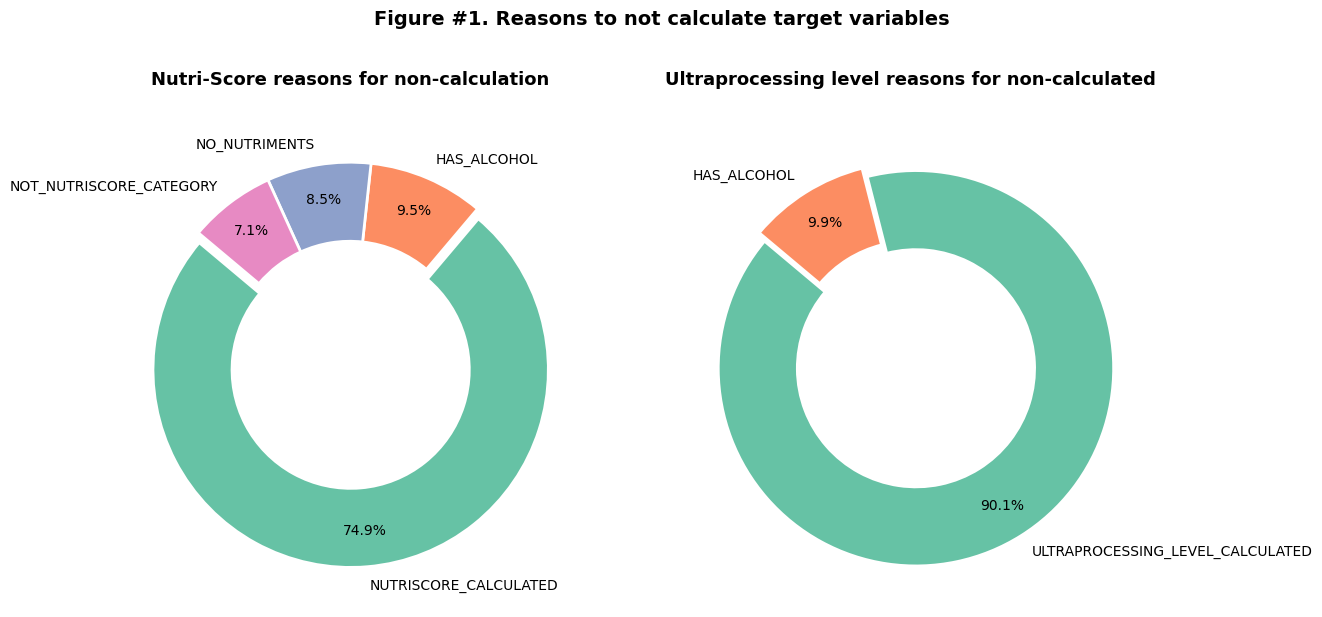

In [26]:
nutri_counts = prepare_status_counts(
    df_unique_product_catalogue, 
    score_col='nutriscore', 
    reason_col='can_nutriscore_be_calculated',
    calculated_label='NUTRISCORE_CALCULATED'
)

ultraprocessing_level_counts = prepare_status_counts(
    df_unique_product_catalogue,
    score_col='ewo_ultra_processed_punctuation',
    reason_col='can_ewo_be_calculated',
    calculated_label='ULTRAPROCESSING_LEVEL_CALCULATED'
)

# planet_score_level_counts = prepare_status_counts(
#     df_unique_product_catalogue,
#     score_col='planetscore',
#     reason_col='can_planet_score_be_calculated', # s'ha de fer!
#     calculated_label='PLANET_SCORE_CALCULATED'
# )

fig, ax = plt.subplots(1, 2, figsize=(14,6))
#fig, ax = plt.subplots(1, 3, figsize=(14,6))

plot_status_donut_piechart(
    nutri_counts, 
    title="Nutri-Score reasons for non-calculation", 
    calculated_label='NUTRISCORE_CALCULATED',
    ax = ax[0]
)

plot_status_donut_piechart(
    ultraprocessing_level_counts,
    title='Ultraprocessing level reasons for non-calculated',
    calculated_label='ULTRAPROCESSING_LEVEL_CALCULATED',
    ax=ax[1]
)

# plot_status_donut_piechart(
#     ultraprocessing_level_counts,
#     title='Planet-Score reasons for non-calculated',
#     calculated_label='PLANET_SCORE_CALCULATED',
#     ax=ax[2]
# )

fig.suptitle(
    "Figure #1. Reasons to not calculate target variables",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()
plt.show()

TODO: Quan estigui tot complet, escriure aqui una miqueta el que indica la taula i els gràfics.

## 3.2. General description of dataset

### 3.2.1. Distribution of products per week and municipality

In this section, the data shown answers the visibility of pairs category and subcategory scraped of online grocery globally in terms of time but distinguishing by locality. This table is interesting because the data obtained is from the **homepage**. Also, it demonstrates whether there are differences between Barcelona and Montferri in terms of the visibility of the categories and subcategories.

In [27]:
def calculate_visibility_distribution_of_products_per_week_and_municipality(df: pd.DataFrame) -> pd.DataFrame:
    """
    Function that generates a DataFrame with the visibility of each category and subcategory and displays
    by mean if there are significant differences between the two localities.

    Args:
        df (pd.DataFrame): DataFrame with product data.

    Returns:
        pd.DataFrame: DataFrame with visibility calculated.    
    """

    weekly_counts = (
        df.groupby(
            ['category', 'subcategory', 'postal_code', 'week_num'],
            observed=False,
        )['id_product']
        .count()
        .reset_index(name='weekly_items')
    )

    municipality_stats = (
        weekly_counts.groupby(
            ['category', 'subcategory', 'postal_code'], observed=False
        )['weekly_items']
        .agg(
            mean='mean',
            std=lambda x: (
                x.std() if len(x) > 1 else 0.0
            ),
        )
        .reset_index()
    )

    municipality_stats['mean_sd'] = municipality_stats.apply(
        lambda r: (
            f"{r['mean']:.1f} (±0.00)"
            if pd.isna(r['std'])
            else f"{r['mean']:.1f} (±{r['std']:.2f})"
        ),
        axis=1,
    )

    pivot_stats = municipality_stats.pivot(
        index=['category', 'subcategory'],
        columns='postal_code',
        values='mean_sd',
    ).reset_index()

    totals = (
        df.groupby(['category', 'subcategory'], observed=True)[
            'id_product'
        ]
        .count()
        .reset_index(name='total_appearances')
    )

    total_scraped = len(df)
    totals['% visibility'] = (
        (totals['total_appearances'] / total_scraped) * 100
    ).round(2)

    visibility_summary = pd.merge(
        totals, pivot_stats, on=['category', 'subcategory'], how='left'
    )

    visibility_summary.rename(columns={"08032": "Can Baró, BCN (Mean±SD)", "43812": "Montferri (Mean±SD)"}, inplace=True)
    visibility_summary.sort_values(
        by='total_appearances', ascending=False, inplace=True
    )

    visibility_summary = visibility_summary.reset_index(drop=True)
    visibility_summary = visibility_summary.sort_values(by='total_appearances', ascending=False)

    return visibility_summary

In [28]:
visibility_summary = calculate_visibility_distribution_of_products_per_week_and_municipality(df_products)

print("Table #11. Top 15 categories and subcategories by online grocery cisibility: Geographic disaggregation and cross-location differences")
visibility_summary.head(15)

Table #11. Top 15 categories and subcategories by online grocery cisibility: Geographic disaggregation and cross-location differences


,category,subcategory,total_appearances,% visibility,"Can Baró, BCN (Mean±SD)",Montferri (Mean±SD)
0,Azúcar caramelos y chocolate,Golosinas,175,9.60,21.8 (±13.18),22.0 (±14.02)
1,Azúcar caramelos y chocolate,Chocolate,129,7.08,16.2 (±1.71),16.0 (±2.71)
2,Bodega,Cerveza,79,4.33,10.2 (±2.22),9.5 (±1.91)
3,Bodega,Licores,64,3.51,8.0 (±0.82),8.0 (±0.82)
4,Cereales y galletas,Galletas,62,3.40,7.5 (±1.29),8.0 (±0.82)
5,Marisco y pescado,Pescado fresco,55,3.02,7.0 (±3.37),6.8 (±3.59)
6,Fruta y verdura,Verdura,54,2.96,7.2 (±3.30),6.2 (±3.30)
7,Aperitivos,Frutos secos y fruta desecada,54,2.96,6.8 (±2.63),6.8 (±2.63)
8,Agua y refrescos,Isotónico y energético,50,2.74,6.2 (±6.08),6.2 (±6.08)
9,Azúcar caramelos y chocolate,Turrones,49,2.69,7.0 (±0.00),5.2 (±3.50)


TODO: Treure una conclusió quan tingui ja totes les dades.

### 3.2.2. Promotion information of the products sample

In [29]:
color_map_type_discounts = {
    'no_promotion': '#bdc3c7',
    'price_discount': '#e74c3c',
    'volume_pack': '#3498db',
    'discounted_pack': '#9b59b6'
}

In [30]:
def generate_promotion_information_by_basic_information(df: pd.DataFrame) -> pd.DataFrame:
    """
    Function to generate promotion information by variables previous_pvp, pvp,
    total_units and is_pack.

    Args:
        df (pd.DataFrame): DataFrame of products.

    Returns:
        pd.DataFrame: An updated DataFrame with new columns.
    """

    df['has_price_discount'] = (
        df['previous_pvp'].notna() & 
        (df['previous_pvp'] > df['pvp'])
    )
    
    df['percentage_discount'] = np.where(
        df['has_price_discount'],
        (((df['previous_pvp'] - df['pvp']) / df['previous_pvp']) * 100).round(2),
        0.0
    )
    
    conditions_pack = [
        (df['total_units'] <= 1) | (df['total_units'].isna()),
        (df['total_units'] == 2),
        (df['total_units'] >= 3)
    ]
    choices_pack = ['single_unit', 'double_pack', 'multiple_pack']
    
    df['pack_format'] = np.select(conditions_pack, choices_pack, default='single_unit')
    
    conditions_promo = [
        (df['has_price_discount'] == True) & (df['is_pack'] == True),
        (df['has_price_discount'] == True) & (df['is_pack'] == False),
        (df['has_price_discount'] == False) & (df['is_pack'] == True),
        (df['has_price_discount'] == False) & (df['is_pack'] == False)
    ]
    choices_promo = [
        'discounted_pack',
        'price_discount',
        'volume_pack',
        'no_promotion'
    ]
    
    df['promotion_type'] = np.select(conditions_promo, choices_promo, default='no_promotion')
    df['is_promoted'] = df['promotion_type'] != 'no_promotion'

    return df

In [31]:
df_products = generate_promotion_information_by_basic_information(df_products)

In the code block cell above, different types of promotion are calculated using the basic variables given, which are `is_pack`, `total_units`, `pvp`, and `previous_pvp`. With those variables, it calculates:
* `has_price_discount`: This variable has a value of $True$ only if a product contains `previous_pvp` informed. If not, it contains $False$.
* `percentage_discount`: This variable contains the percentage of discount done following the formula: $\frac{previouspvp - pvp}{pvp}*100$. It only applies if `has_percentage_discount` is $True$. Otherwise, it has a value of $0$.
* `pack_format`: Discretises the variable `total_units` with three posibilities: *single_unit*, *double_pack*, and *multiple_pack*.
* `promotion_type`: By using the variables already explained, this is the most interesting variable about promotions. This can have different values:
    * *discounted_pack*: When a product has a price discount and is a pack, both variables are $True$.
    * *price_discount*: When a product has a price discount ($True$) and is not a pack ($False$).
    * *volume_pack*: When a product doesn't have a price discount ($False$), but is a pack ($True$).
    * *no_promotion*: When a product doesn't have a price discount and doesn't is a pack, both variables are $False$.
* `is_promoted`: Global variable whether is $True$ when `promotion_type` is not $nopromotion$.

With this information, we can calculate total food products scraped and information about promotions.

In [32]:
def calculate_information_per_week_postal_code_and_categories_subcategories_promotion_and_coverage_food_products(
    df_products: pd.DataFrame,
    df_aggregation: pd.DataFrame
) -> pd.DataFrame:
    """
    Function that generates a DataFrame context joining the aggregates DataFrame and products Dataframe to
    display total products scraped, items promoted, % of items coverage and % of items promoted for each
    week, postal code, category and subcategory.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        df_aggregation (pd.DataFrame): DataFrame with aggregated data (total items) for each category 
                                       and subcategory, week number and postal code.
    Returns:
        pd.DataFrame: DataFrame with the information.
    """
    df_prod_agg = (
        df_products.groupby(
            ['week_num', 'postal_code', 'category_norm', 'subcategory_norm'], observed=True
        )
        .agg(
            items_obtained_by_scraping=('id_product', 'nunique'),
            items_promoted=(
                'is_promoted',
                lambda x: (x == True).sum(),
            ),
        )
        .reset_index()
    )
    
    df_context = pd.merge(
        df_aggregation,
        df_prod_agg,
        on=['week_num', 'postal_code', "category_norm", 'subcategory_norm'],
        how='left',
    )
    
    df_context['items_obtained_by_scraping'] = df_context['items_obtained_by_scraping'].fillna(0).astype(int)
    df_context['items_promoted'] = (
        df_context['items_promoted'].fillna(0).astype(int)
    )
    
    df_context['% coverage'] = np.where(
        df_context['total_items'] > 0,
        (df_context['items_obtained_by_scraping'] / df_context['total_items']) * 100,
        0
    ).round(2)
    
    df_context['% products under promotion'] = np.where(
        df_context['items_obtained_by_scraping'] > 0,
        (df_context['items_promoted'] / df_context['items_obtained_by_scraping']) * 100,
        0,
    ).round(2)
    
    columns_order = ['week_num', 'postal_code', 'category', 'subcategory', 'items_obtained_by_scraping', 'total_items', 'items_promoted', '% coverage', '% products under promotion']
    
    final_cols = [col for col in columns_order if col in df_context.columns]
    df_context_summary = df_context[final_cols]
    
    df_context_summary.sort_values('items_obtained_by_scraping', ascending=False)

    return df_context_summary

In [33]:
df_context_summary = calculate_information_per_week_postal_code_and_categories_subcategories_promotion_and_coverage_food_products(
    df_products,
    df_aggregation
)

print("Table #12. Weekly scraping coverage and promotional prevalence by postal code and category")
df_context_summary

Table #12. Weekly scraping coverage and promotional prevalence by postal code and category


,week_num,postal_code,category,subcategory,items_obtained_by_scraping,total_items,items_promoted,% coverage,% products under promotion
0,40,43812,"Aceite, especias y salsas","Aceite, vinagre y sal",10,37,10,27.03,100.00
1,40,43812,"Aceite, especias y salsas",Especias,0,49,0,0.00,0.00
2,40,43812,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza",2,19,2,10.53,100.00
3,40,43812,"Aceite, especias y salsas",Otras salsas,2,39,0,5.13,0.00
4,40,43812,Agua y refrescos,Agua,0,49,0,0.00,0.00
...,...,...,...,...,...,...,...,...,...
858,43,08032,Postres y yogures,Yogures y postres infantiles,0,8,0,0.00,0.00
859,43,08032,Zumos,Fruta variada,3,28,2,10.71,66.67
860,43,08032,Zumos,Melocotón y piña,1,10,1,10.00,100.00
861,43,08032,Zumos,Naranja,1,12,1,8.33,100.00


TODO: Quan tingui totes les dades, extreure'n conclusions d'aquí, taula la qual dona informació agregada per setmana, codi postal, categoria, subcategoria, el total de productes obtinguts via scraping, el total d'items en la categoria i subcategoria, els promocionats, el %coverage es % entre els productes obtinguts i els que hi ha en total, i el % de productes sota alguna promoció.

In [34]:
def plot_promotion_data_donut_piechart(df: pd.DataFrame, color_map: dict = color_map_type_discounts) -> None:
    """
    Function that prints a donut piechart with the different types of promotions
    and the percentages of each.

    Args:
        df (pd.DataFrame): DataFrame of the data.
        color_map (dict): Colors of discounts type.

    Returns:
        None. It only prints out the graphic.
    """

    counts = df['promotion_type'].value_counts()
    
    colors = [color_map[x] for x in counts.index]
    explode = [0.05 for x in counts.index]
    
    fig, ax = plt.subplots(figsize=(8, 6))
    wedges, texts, autotexts = ax.pie(
        counts.values,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.8,
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
    )
    
    plt.setp(autotexts, size=10, weight="bold")
    ax.set_title("Figure #2. Distribution of promoted products vs no promotion", fontsize=13, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

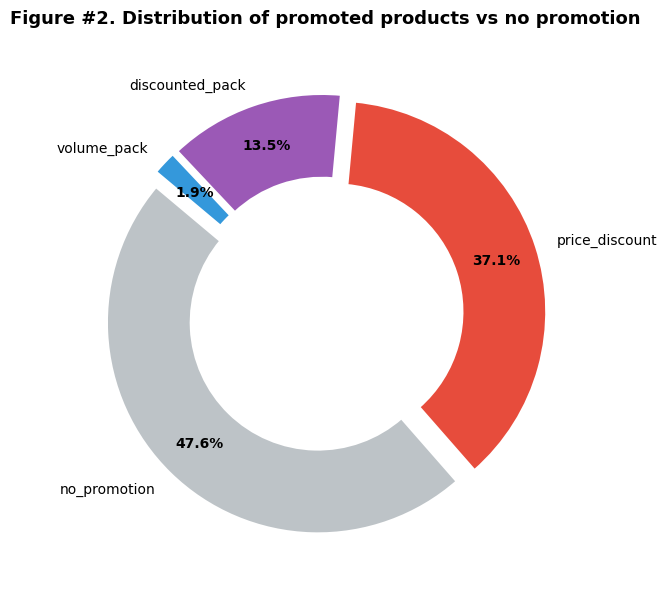

In [35]:
plot_promotion_data_donut_piechart(df_products)

TODO: Quan tingui totes les dades, llavors fer l'explicació que toqui.

In [36]:
def plot_promotion_by_category_stacked(df: pd.DataFrame, color_map: dict = color_map_type_discounts) -> None:
    """
    Function that generates an horizontal bar char showing each category and the percentage distribution
    of type of discount for each category.

    Args:
        df (pd.DataFrame): DataFrame of products data.
        color_map (dict): Color map of the discounts type.

    Returns:
        None. Prints out the graphic.
    """

    ct = pd.crosstab(df['category'], df['promotion_type'], normalize='index') * 100
    desired_order = ['no_promotion', 'price_discount', 'volume_pack', 'discounted_pack']
    cols = [c for c in desired_order if c in ct.columns]
    ct = ct[cols]
    ct = ct.sort_values(by='no_promotion', ascending=True)

    colors = [color_map[c] for c in ct.columns]
    
    fig, ax = plt.subplots(figsize=(11, 7))
    ct.plot(kind='barh', stacked=True, color=colors, ax=ax, width=0.7)

    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        if width > 5:
            x, y = p.get_xy() 
            ax.text(x + width/2, y + height/2, f"{width:.1f}%", 
                    ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
            
    ax.set_title("Figure #3. Tipology of promotions for each category", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Percentage of products (%)", fontsize=11)
    ax.legend(title="Promotion type", bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

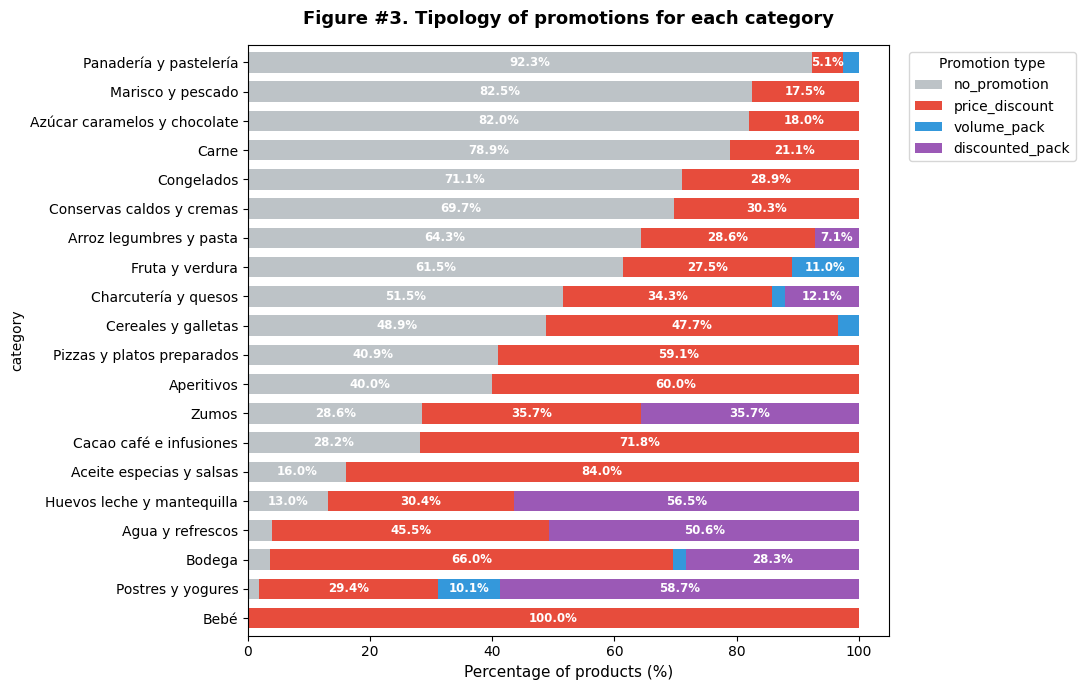

In [37]:
plot_promotion_by_category_stacked(df_products)

TODO: Quan tingui totes les dades, llavors fer l'explicació que toqui.

In [38]:
def plot_promotion_by_category_and_subcategory(df: pd.DataFrame, color_map: dict = color_map_type_discounts) -> None:
    """
    Function that generates horizontal bar plot for promotion types by category and each subcategory.

    Args:
        df (pd.DataFrame): Dataframe of products.
        color_map (dict): Dictionary with colours.

    Returns:
        None. Prints out the graphic.
    """
    
    ct_sub = pd.crosstab([df['category'], df['subcategory']], df['promotion_type'], normalize='index') * 100
    ct_cat = pd.crosstab(df['category'], df['promotion_type'], normalize='index') * 100

    ct_sub = ct_sub.dropna(how='all')
    ct_cat = ct_cat.dropna(how='all')

    desired_order = ['no_promotion', 'price_discount', 'volume_pack', 'discounted_pack']
    cols = [c for c in desired_order if c in ct_cat.columns]

    if 'no_promotion' in ct_cat.columns:
        cat_order = ct_cat['no_promotion'].sort_values(ascending=False).index
    else:
        cat_order = ct_cat.index

    colors = [color_map[c] for c in cols]

    y_positions = []
    y_labels = []
    bar_heights = []
    is_main_list = []
    data_rows = []

    current_y = 0
    cat_separator_positions = []

    for i, cat in enumerate(reversed(cat_order)):
        if cat in ct_sub.index.get_level_values(0):
            sub_data = ct_sub.loc[cat]
            for subcat in reversed(sub_data.index):
                data_rows.append(sub_data.loc[subcat, cols].values)
                y_positions.append(current_y)
                y_labels.append(f"{subcat}")
                bar_heights.append(0.38) 
                is_main_list.append(False)
                current_y += 1.0

        if cat in ct_cat.index:
            data_rows.append(ct_cat.loc[cat, cols].values)
            y_positions.append(current_y)
            y_labels.append(str(cat).upper())
            bar_heights.append(0.65)
            is_main_list.append(True)
            current_y += 1.2

        if i < len(cat_order) - 1:
            cat_separator_positions.append(current_y + 0.3)
            current_y += 0.8

    if len(y_positions) == 0:
        print("No hi ha dades per mostrar.")
        return

    data_matrix = np.array(data_rows)

    fig_height = max(6, len(y_positions) * 0.45)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    lefts = np.zeros(len(y_positions))
    for col_idx, col_name in enumerate(cols):
        widths = data_matrix[:, col_idx]
        bars = ax.barh(
            y_positions, 
            widths, 
            left=lefts, 
            height=bar_heights, 
            color=colors[col_idx], 
            label=col_name,
            edgecolor='white',
            linewidth=0.8
        )

        for idx, (bar, width) in enumerate(zip(bars, widths)):
            if not np.isnan(width) and width > 5.5:
                y_pos = bar.get_y() + bar.get_height() / 2
                x_pos = lefts[idx] + width / 2
                font_weight = 'bold' if is_main_list[idx] else 'normal'
                font_size = 8.5 if is_main_list[idx] else 7.5
                ax.text(
                    x_pos, y_pos, f"{width:.1f}%", 
                    ha='center', va='center', color='white', 
                    fontweight=font_weight, fontsize=font_size
                )
        lefts += widths

    for sep_y in cat_separator_positions:
        ax.axhline(y=sep_y, color='#dcdde1', linestyle='--', linewidth=0.9)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels, fontsize=9)

    for tick_label, is_main in zip(ax.get_yticklabels(), is_main_list):
        if is_main:
            tick_label.set_fontweight('bold')
            tick_label.set_fontsize(10)

    ax.set_ylim(min(y_positions) - 0.8, max(y_positions) + 0.8)
    ax.set_title("Figure #4. Tipology of promotions by food category and subcategory", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Product percentage (%)", fontsize=11)
    ax.set_xlim(0, 100)
    ax.legend(title="Promotion type", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

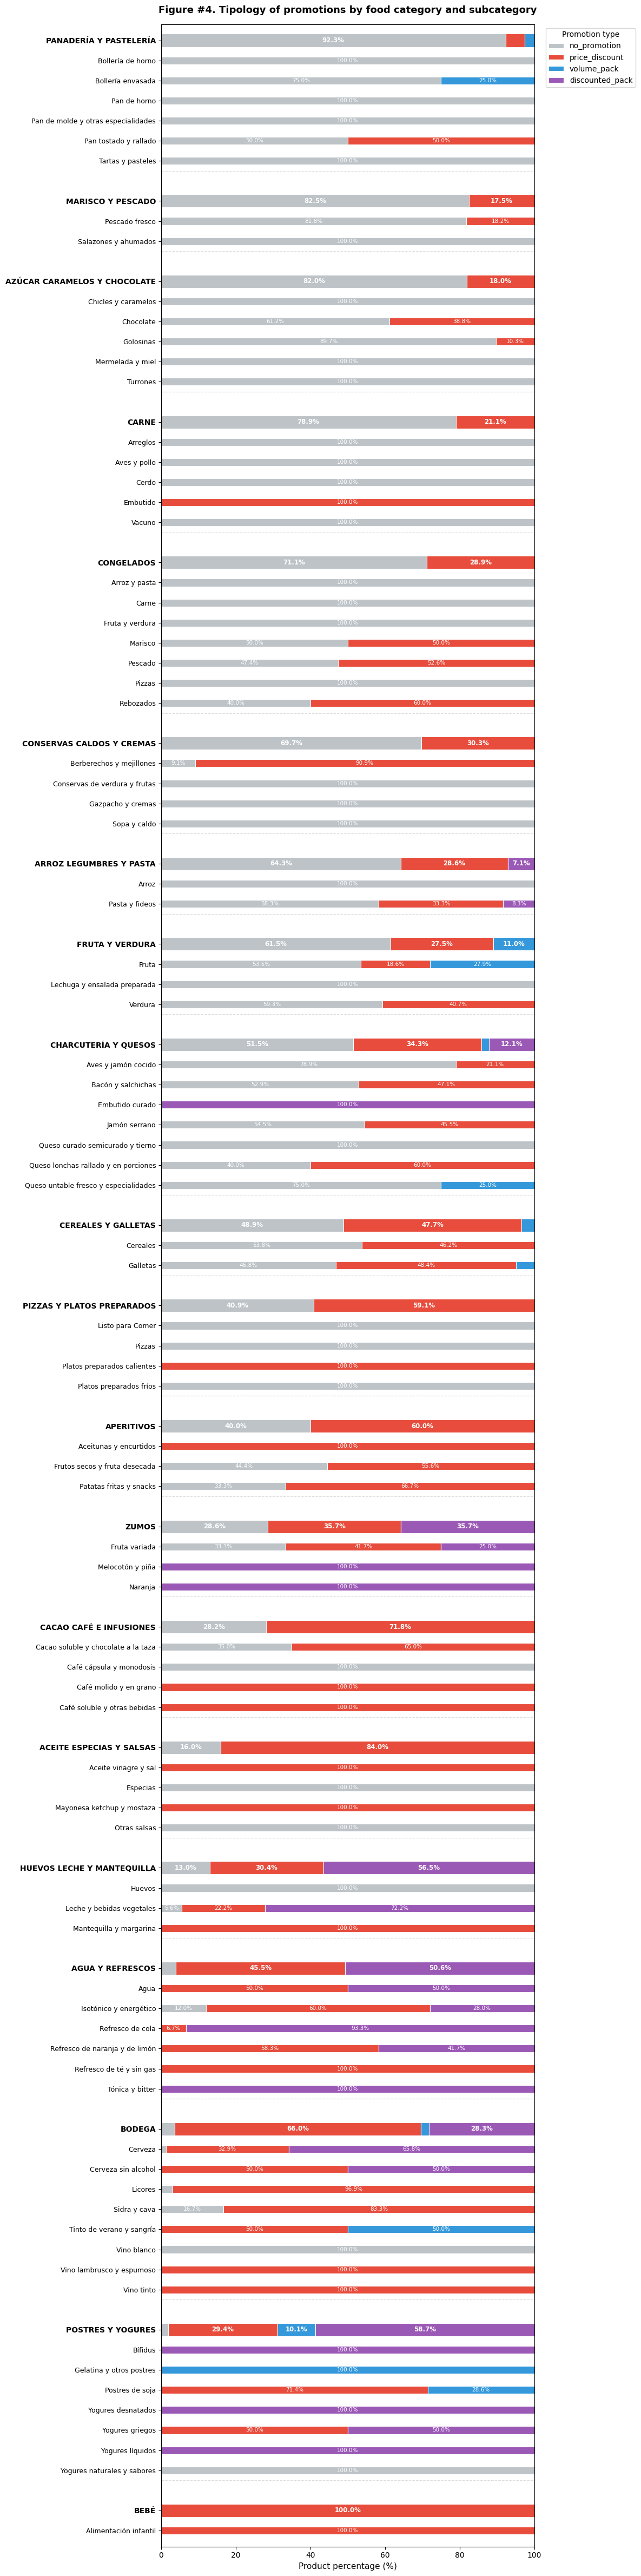

In [39]:
plot_promotion_by_category_and_subcategory(df_products)

TODO: Quan tingui totes les dades, llavors fer l'explicació que toqui.

In [40]:
def get_mean_confidence_interval(series: pd.core.series.Series, cl: float = CL) -> str:
    """
    Function that calculates a confidence interval for a mean (continuous variable).
    To do this, it applies the Standard Error of the Mean and Student t with n-1
    degrees of freedom over the mean. By using theory, a test over the mean
    with population desviation unknown, it uses the statistical test Student t with n-1
    degrees of freedom.

    Args:
        series (pd.core.series.Series): List of the data.
        cl (float): Confidence level.

    Returns:
        str: String with the data.
    """
    s = series.dropna()
    n = len(s)

    if n < 1:
        return 'N/A'
    if n == 1:
        mean = s.iloc[0]
        return f'{mean:.2f}% [N/A]'
    
    mean = np.mean(s)
    sem = stats.sem(s)

    if sem == 0 or np.isnan(sem):
        return f'{mean:.2f}% [{mean:.2f}%, {mean:.2f}%]'

    ci_lower, ci_upper = stats.t.interval(cl, df=n - 1, loc=mean, scale=sem)

    if np.isnan(ci_lower) or np.isnan(ci_upper):
        return f'{mean:.2f}% [{mean:.2f}%, {mean:.2f}%]'

    return f'{mean:.2f}% [{ci_lower:.2f}%, {ci_upper:.2f}%]'

def verify_clt_for_proportions(series: pd.core.series.Series) -> bool:
    """
    Function to check if for the data applies the Central Limit Theory for proportions.

    Args:
        series (pd.core.series.Series): List of the data.

    Returns:
        bool: True if CLT is applied, False no.
    """

    n = len(series)
    successes = np.sum(series)
    failures = n - successes

    if successes <= 5 or failures <= 5:
        return False

    return True


def get_proportion_confidence_interval(series: pd.core.series.Series, cl: float = CL) -> str:
    """
    Confidence interval for a proportion or percentage (binary variable). According to the
    theory of the probability, if the size of a sample is sufficently big, the variable
    follows a normal distribution. So, this function checks this and executes this theory.

    Args:
        series (pd.core.series.Series): Data to be avaluated.
        cl (float): Confidence level.

    Returns:
        str: Data calculated.
    """
    s = series.dropna()
    n = len(s)
    if n == 0:
        return "N/A"
    
    p = np.mean(s)
    pct = p * 100
    clt_is_applied = verify_clt_for_proportions(s)

    if not clt_is_applied:
        if p == 0.0:
            return '0.0% [0.0%, 0.0%]'
        if p == 1.0:
            return '100.0% [100.0%, 100.0%]'
        return f'{pct:.1f}% [Insufficient size]'
    
    se = np.sqrt((p * (1 - p)) / n)
    ci_lower, ci_upper = stats.norm.interval(cl, loc=p, scale=se)
    ci_l = max(0.0, ci_lower * 100)
    ci_u = min(100.0, ci_upper * 100)

    return f'{pct:.1f}% [{ci_l:.1f}%, {ci_u:.1f}%]'

def calculate_promotion_proportions(series_promo: pd.core.series.Series, cl: float = CL) -> tuple:
    """
    Function that calculates the percentage and the margin of errors with the interval of confidence of 95%
    of proportions by using the CLT criteria to apply CI over proportion, using the theory of probability.

    Args:
        series_promo (pd.core.series.Series): Data under promotion.
        cl (float): Confidence level.

    Returns:
        tuple: percentage, error_low, error_high
    """
    s = series_promo.dropna()
    n = len(s)
    if n == 0:
        return 0.0, 0.0, 0.0
    p = np.mean(s)
    pct = p * 100

    clt_is_applied = verify_clt_for_proportions(s)

    if not clt_is_applied:
        return pct, 0.0, 0.0
    
    se = np.sqrt(p * (1 - p) / n)
    ci_l, ci_u = stats.norm.interval(cl, loc=p, scale=se)
    ci_l = max(0.0, ci_l)
    ci_u = min(1.0, ci_u)
    
    err_low = (p - ci_l) * 100
    err_high = (ci_u - p) * 100

    return pct, err_low, err_high


def calculate_table_to_retireve_confidence_intervals_for_products_discounted_and_packs(
    df_products: pd.DataFrame,
    df_aggregation: pd.DataFrame
) -> pd.DataFrame:
    """
    Function to calculate table to retrieve information about discounts per price and packs information, each one with
    confidence interval of 95%.

    Args:
        df_products (pd.DataFrame): Dataframe with product information.

    Return:
        pd.DataFrame: DataFrame with data.
    """

    items_table = []
    for (cat_norm, subcat_norm), group in df_products.groupby(['category_norm', 'subcategory_norm'], observed=True):
        cat_display = group['category'].iloc[0]
        subcat_display = group['subcategory'].iloc[0]
        
        total_n = df_aggregation[
            (df_aggregation['category_norm'] == cat_norm)
            & (df_aggregation['subcategory_norm'] == subcat_norm)
        ]['total_items'].sum()
    
        homepage_n = group['title_category_main_page'].notna().sum()
        
        disc_prop_str = get_proportion_confidence_interval(group['has_price_discount'])
        disc_products = group[group['has_price_discount'] == True]['percentage_discount']
        
        disc_mag_str = (
            get_mean_confidence_interval(disc_products)
            if len(disc_products) > 0
            else '0.00%'
        )
        
        packs_prop_str = get_proportion_confidence_interval(group['is_pack'])
        
        pack_units = group[group['is_pack'] == True]['total_units'].dropna()
        if len(pack_units) > 1 and pack_units.std() is not np.nan:
            units_mean_sd = f'{pack_units.mean():.2f} (SD: {pack_units.std():.2f})'
        elif len(pack_units) == 1:
            units_mean_sd = f'{pack_units.mean():.2f} (SD: 0.00)'
        else:
            units_mean_sd = 'N/A'
            
        items_table.append({
            'Category': cat_display,
            'Subcategory': subcat_display,
            'Homepage (n)': homepage_n,
            'Total (n)': total_n,
            'Products Discounted (%; 95% CI)': disc_prop_str,
            'Magnitude of Discount (% Change; 95% CI)': disc_mag_str,
            'Products on packs (%; 95% CI)': packs_prop_str,
            'Units in packs (Mean; SD)': units_mean_sd
        })
    
    table_results_df = pd.DataFrame(items_table)

    return table_results_df

In [41]:
table_results_df = calculate_table_to_retireve_confidence_intervals_for_products_discounted_and_packs(df_products, df_aggregation)

print("Table #13. Online grocery choice architecture and promotional strategies:\
 Homepage visibility, Price discount prevalence, and pack offerings by product category")
table_results_df

Table #13. Online grocery choice architecture and promotional strategies: Homepage visibility, Price discount prevalence, and pack offerings by product category


,Category,Subcategory,Homepage (n),Total (n),Products Discounted (%; 95% CI),Magnitude of Discount (% Change; 95% CI),Products on packs (%; 95% CI),Units in packs (Mean; SD)
0,Aceite especias y salsas,Aceite vinagre y sal,34,301,"100.0% [100.0%, 100.0%]","3.69% [3.26%, 4.11%]","0.0% [0.0%, 0.0%]",N/A
1,Aceite especias y salsas,Especias,2,396,"0.0% [0.0%, 0.0%]",0.00%,"0.0% [0.0%, 0.0%]",N/A
2,Aceite especias y salsas,Mayonesa ketchup y mostaza,8,152,"100.0% [100.0%, 100.0%]","17.54% [13.74%, 21.35%]","0.0% [0.0%, 0.0%]",N/A
3,Aceite especias y salsas,Otras salsas,6,309,"0.0% [0.0%, 0.0%]",0.00%,"0.0% [0.0%, 0.0%]",N/A
4,Agua y refrescos,Agua,8,398,"100.0% [100.0%, 100.0%]","8.00% [8.00%, 8.00%]",50.0% [Insufficient size],6.00 (SD: 0.00)
...,...,...,...,...,...,...,...,...
81,Postres y yogures,Yogures líquidos,24,248,"100.0% [100.0%, 100.0%]","12.49% [10.40%, 14.59%]","100.0% [100.0%, 100.0%]",11.00 (SD: 1.02)
82,Postres y yogures,Yogures naturales y sabores,2,160,"0.0% [0.0%, 0.0%]",0.00%,"0.0% [0.0%, 0.0%]",N/A
83,Zumos,Fruta variada,24,224,"66.7% [47.8%, 85.5%]","18.41% [14.26%, 22.55%]","25.0% [7.7%, 42.3%]",3.00 (SD: 0.00)
84,Zumos,Melocotón y piña,2,80,"100.0% [100.0%, 100.0%]","3.13% [3.13%, 3.13%]","100.0% [100.0%, 100.0%]",6.00 (SD: 0.00)


Before continue the exploratory data analysis, it is important to add some statistical theory for two functions used in this table:

**Explanation of how the function *get_mean_confidence_interval* works**

In this case, we do not know the population deviation, and therefore, the contrast statistic used to calculate the confidence interval is Student's *t* with $n - 1$ degrees of freedom.

$$
t=\frac{\bar{x}-\mu_0}{\frac{s}{\sqrt{n}}} \sim t_{n-1}
$$

This is why, to calculate the confidence intervals for the mean, the *get_mean_confidence_interval* function is used, which internally applies *stats.t.interval* with a 95% confidence level for the mean, using the SEM as the scale, which is the denominator of Student's *t*.

**Explanation of how the function *get_proportion_confidence_interval* works**

The confidence interval for the proportion, according to probability theory, states that if the sample size is sufficiently large, the variable follows a standard normal distribution:

$$
z=\frac{\hat{p}-p}{\sqrt{\frac{p(1-p)}{n}}} \sim  N(0,1)
$$

And the standard error, follows the formula:

$$
SE = \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

Then, the function also checks and validates, in accordance with the Central Limit Theorem, whether the sample is sufficiently large, according to statistical theory, which states: "Let $X$ be a random variable with a binomial distribution of parameters *n* and *p*. If *n* is large, then the distribution is approximately normal with mean $\mu=np$ and variance $\sigma^2=np(1-p)$. In practice, this approximation is commonly used when both $np$ and $n(1-p)$ are greater than $5$.

Once this has been detected, then the normal approximation is or is not used to calculate the confidence intervals.

TODO: treure conclusions quan tingui totes les dades.

#### 3.2.2.1. Promotion types and target variables

In [42]:
def plot_promoted_percentage_by_score(df: pd.DataFrame) -> None:
    """
    Function that generates graphic with confidence interval of 95% of the
    different target variables.

    Args:
        df (pd.DataFrame): DataFrame with product data.

    Returns:
        None. It prints out the graphic.
    """

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    configs = [
        {'col': 'nutriscore', 'name': 'Nutri-Score', 'levels': ['A', 'B', 'C', 'D', 'E'], 'ax_idx': 0},
        {'col': 'ewo_ultra_processed_punctuation', 'name': 'Ewö', 'levels': [1.0, 2.0, 3.0, 4.0], 'ax_idx': 1},
        {'col': 'planetscore', 'name': 'Planet-Score', 'levels': ['A', 'B', 'C', 'D', 'E'], 'ax_idx': 2}
    ]
    
    for cfg in configs:
        ax = axes[cfg['ax_idx']]
        col = cfg['col']
        
        has_data = col in df.columns and df[col].notna().sum() > 0
        
        if not has_data:
            ax.text(0.5, 0.5, f"NO DATA YET\n({cfg['name'].upper()})", 
                    ha='center', va='center', fontsize=11, fontweight='bold', color='#7f8c8d')
            ax.set_title(f"% Promoted by {cfg['name']}", fontweight='bold', fontsize=12)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            continue
            
        pcts, errs_low, errs_high, x_labels = [], [], [], []
        for level in cfg['levels']:
            sub = df[df[col] == level]['is_promoted']
            pct, err_l, err_h = calculate_promotion_proportions(sub)
            pcts.append(pct)
            errs_low.append(err_l)
            errs_high.append(err_h)
            x_labels.append(str(level))
            
        x = np.arange(len(x_labels))
        
        bars = ax.bar(
            x, pcts, 
            yerr=[errs_low, errs_high], 
            capsize=4, 
            color='white', 
            edgecolor='black', 
            linewidth=1.2,
            error_kw=dict(ecolor='black', lw=1.2, capsize=4, capthick=1.2)
        )
        
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels)
        ax.set_ylabel('% Promoted', fontsize=11, fontweight='bold')
        ax.set_title(f"% Promoted by {cfg['name']}", fontweight='bold', fontsize=12, pad=15)
        
        max_y = max([p + e for p, e in zip(pcts, errs_high)]) if len(pcts) > 0 else 50
        ax.set_ylim(0, max(50, max_y + 12))
        
        for i, (p, e_h) in enumerate(zip(pcts, errs_high)):
            if p > 0:
                ax.text(i, p + e_h + 1.5, f"{int(round(p))}", ha='center', va='bottom', fontsize=10, fontweight='bold')
                
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)


    fig.suptitle(
    'Figure #5. Promotional prevalence across nutritional, processing, and environmental'
    ' quality indicators (95% CI)',
    fontsize=14,
    fontweight='bold',
    y=1.05,
    )
    plt.tight_layout()
    plt.show()

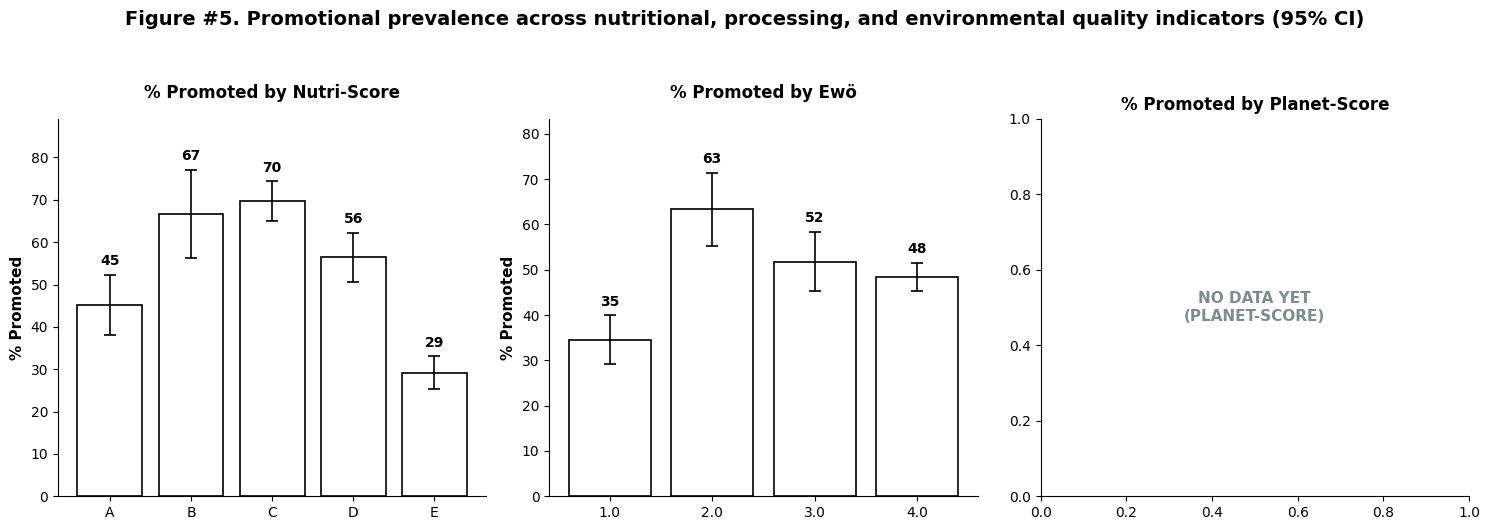

In [43]:
plot_promoted_percentage_by_score(df_products)

This graph shows the probability that a product is promoted given that it belongs to category A (or B, C, D, E) for the Nutri-Score, 1 (or 2, 3, 4) for the Ewö level of ultra-processing, and A (or B, C, D, E) for the Planet-Score.

**Theoretical reasoning for the function *calculate_promotion_proportions***

Since we are reviewing proportions, we find ourselves in the same position as in the previous case, so we apply the same theoretical concept as before.

$$
z=\frac{\hat{p}-p}{\sqrt{\frac{p(1-p)}{n}}} \sim  N(0,1)
$$

And the standard error follows the formula:

$$
SE = \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$


## 3.3. General distribution of target variables

### 3.3.1. Plotting general distribution of target variables

In [44]:
all_categories = sorted(df_products['category'].unique())

def plot_score_heatmaps_by_category(
    df: pd.DataFrame,
    colors: str,
    title_text: str,
    xlabel: str,
    figsize: tuple = (10, 8)
) -> None:
    """
    Function that generates a heatmap with the count of total items for each category and target variable.

    Args:
        df (pd.DataFrame): Data to be printed.
        colors (str): String colour palette to be used.
        title_text (str): Title of the graphic.
        xlabel (str): Label of the x axis.
        figsize (tuple): Indicates the size of the figure.

    Returns:
        None. Prints out the heatmap.
    """

    plt.figure(figsize=figsize)
    
    sns.heatmap(
        df,
        annot=True,
        fmt='d',
        cmap=colors,
        cbar_kws={'label': 'Number of products'},
        linewidths=0.5,
        linecolor='white'
    )

    plt.title(title_text, fontweight='bold', fontsize=12)
    plt.xlabel(xlabel, fontsize=11, fontweight='bold', labelpad=10)
    plt.ylabel('Category', fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(rotation=0, ha='center', fontsize=9.5)
    plt.yticks(rotation=0, fontsize=9.5)

    plt.tight_layout()
    plt.show()

In [45]:
def plot_heatmap_number_products_category_nutri_score(df_products: pd.DataFrame, all_categories: list) -> None:
    """
    Function that generates a heatmap with count products by category and nutriscore.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        all_categories (list): List of all categories.

    Returns:
        None. Prints out the heatmap.
    """
    ct_nutri = (
        pd.crosstab(df_products['category'], df_products['nutriscore'])
        .reindex(index=all_categories, columns=['A', 'B', 'C', 'D', 'E'])
        .fillna(0)
        .astype(int)
    )
    
    plot_score_heatmaps_by_category(ct_nutri, 'OrRd', 'Figure #6. Number of products by category and Nutri-Score', 'Nutri-Score letter')

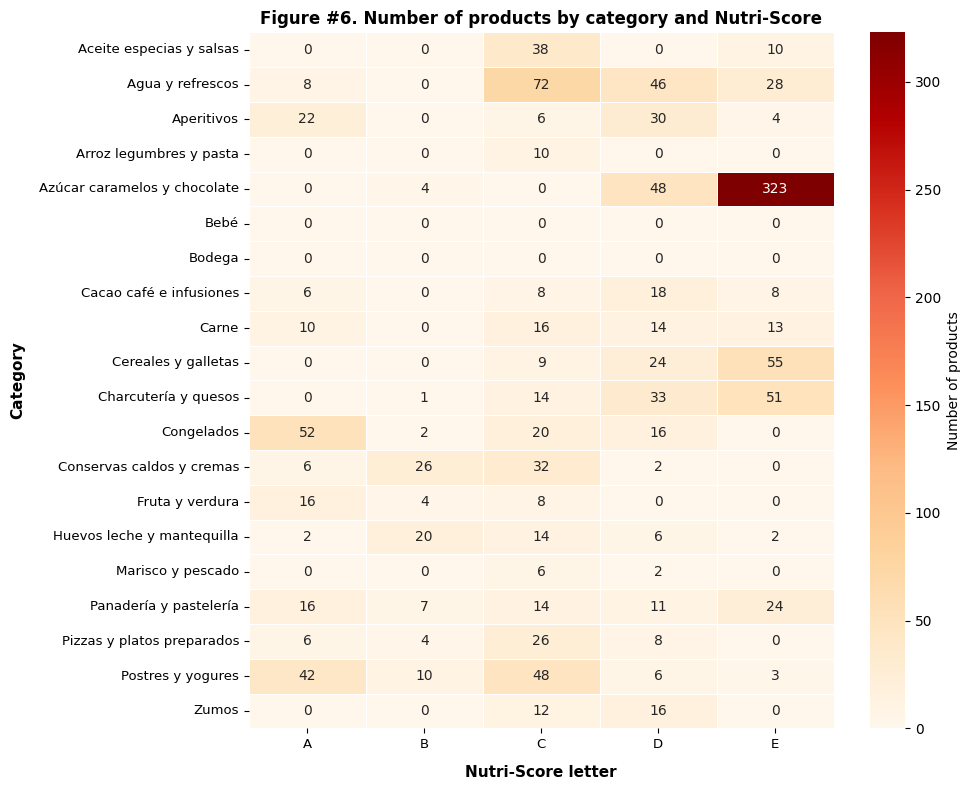

In [46]:
plot_heatmap_number_products_category_nutri_score(df_products, all_categories)

TODO: Treure conclusions quan tingui totes les dades.

In [47]:
def plot_heatmap_number_products_category_ewo(df_products: pd.DataFrame, all_categories: list) -> None:
    """
    Function that generates a heatmap with count products by category and Ewö ultraprocessing level.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        all_categories (list): List of all categories.

    Returns:
        None. Prints out the heatmap.
    """
    ct_ewo = (
        pd.crosstab(df_products['category'], df_products['ewo_ultra_processed_punctuation'])
        .reindex(index=all_categories, columns=[1.0, 2.0, 3.0, 4.0])
        .fillna(0)
        .astype(int)
    )
    
    ct_ewo.columns = ['1.0 (Minimum)','2.0 (Processed)','3.0 (High-processed)','4.0 (Ultraprocessed)']
    
    plot_score_heatmaps_by_category(
        ct_ewo,
        'OrRd',
        'Figure #7. Number of products by category and Ewö ultraprocessing level', 'Ewö ultraprocessing level'
    )

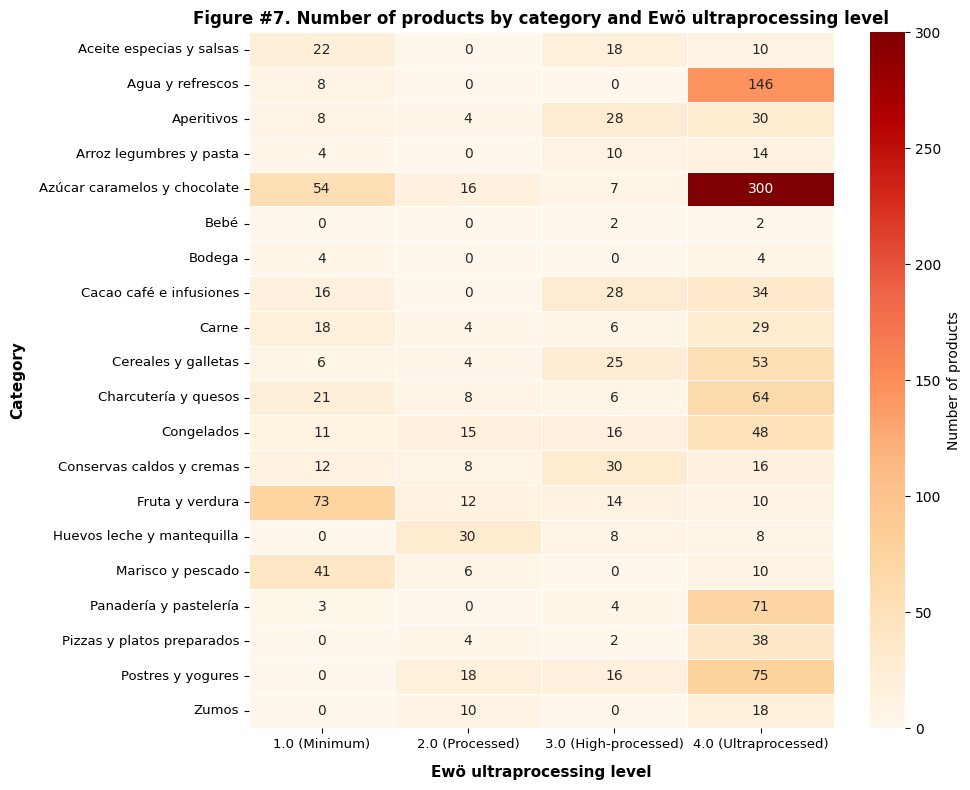

In [48]:
plot_heatmap_number_products_category_ewo(df_products, all_categories)

TODO: Treure conclusions quan tingui totes les dades.

In [49]:
def plot_heatmap_number_products_category_planet_score(df_products: pd.DataFrame, all_categories: list) -> None:
    """
    Function that generates a heatmap with count products by category and Planet-Score.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        all_categories (list): List of all categories.

    Returns:
        None. Prints out the heatmap.
    """
    
    ct_planet = (
        pd.crosstab(df_products['category'], df_products['planetscore'])
        .reindex(index=all_categories, columns=['A', 'B', 'C', 'D', 'E'])
        .fillna(0)
        .astype(int)
    )
    
    plot_score_heatmaps_by_category(ct_planet, 'OrRd', 'Figure #8. Number of products by category and Planet-Score', 'Planet-Score')

In [50]:
# plot_heatmap_number_products_category_planet_score(df_products, all_categories)

TODO: Treure conclusions quan tingui totes les dades.

### 3.3.2. Plotting target variables in comparison with postal code and week number

In [51]:
def build_week_labels(df: pd.DataFrame) -> dict:
    """
    Function to generate label weeks for heatmaps that uses week numbers.
    The string generated is like 'Week X\n(DD/MM/YYYY)'

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        dict: The equivalence of week number and string.
    """
    week_dates = (
        df.groupby('week_num')['date_scraped'].min().sort_index().reset_index()
    )

    week_dates['rel_week'] = range(1, len(week_dates) + 1)

    week_dates['label'] = week_dates.apply(
        lambda r: f"Week {r['rel_week']}\n({r['date_scraped'].strftime('%d/%m/%Y')})",
        axis=1,
    )

    return dict(zip(week_dates['week_num'], week_dates['label']))

def get_mean_std_pivots(df: pd.DataFrame, value_col: str, week_label_map: dict) -> tuple:
    """
    Function that calculates the means and std to print out into the heatmaps
    and renames the week columns.

    Args:
        df (pd.DataFrame): DataFrame with the data.
        value_col (str): Column to be used.
        week_label_map (dict): Dictionary with week labels.

    Returns:
        tuple: mean dataframe and dataframe with information.
    
    """
    p_mean = df.pivot_table(
        index='postal_code',
        columns='week_num',
        values=value_col,
        aggfunc='mean',
    )
    p_std = df.pivot_table(
        index='postal_code',
        columns='week_num',
        values=value_col,
        aggfunc='std',
    )

    annot_df = p_mean.copy().astype(str)
    for row in p_mean.index:
        for col in p_mean.columns:
            m = p_mean.loc[row, col]
            s = p_std.loc[row, col]
            if pd.isna(m):
                annot_df.loc[row, col] = ''
            elif pd.isna(s):
                annot_df.loc[row, col] = f'{m:.2f}\n(±0.00)'
            else:
                annot_df.loc[row, col] = f'{m:.2f}\n(±{s:.2f})'

    if week_label_map:
        p_mean.rename(columns=week_label_map, inplace=True)
        annot_df.rename(columns=week_label_map, inplace=True)

    return p_mean, annot_df

def plot_temporal_heatmap(
    df: pd.DataFrame,
    annotation: pd.DataFrame,
    color: str,
    legend_name: str,
    title_text: str,
    figsize: tuple = (8, 5)
) -> None:
    """
    Function that generates temporal heatmaps showing means and standard deviation (±SD)

    Args:
        df (pd.DataFrame): DataFrame with data.
        annotation (pd.DataFrame): DataFrame with information about mean and standard deviation.
        color (str): Color palette.
        legend_name (str): Text to display in legend.
        title_text (str): Title of the graphic.
        figsize (tuple): Figure size.

    Returns:
        None. Prints out the graphic.
    """

    plt.figure(figsize=figsize)

    sns.heatmap(
        df,
        annot=annotation,
        fmt='',
        annot_kws={'size': 8},
        cmap=color,
        cbar_kws={'label': legend_name},
    )

    plt.title(title_text, fontweight='bold', fontsize=12)
    plt.ylabel('Postal code', fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(rotation=0, ha='center', fontsize=9.5)
    plt.yticks(rotation=0, fontsize=9.5)

    plt.tight_layout()
    plt.show()

week_label_map = build_week_labels(df_products)

In [52]:
def plot_heatmap_week_nutri_score(df_products: pd.DataFrame, week_label_map: dict) -> None:
    """
    Function that plots information about how change nutriscore per week using mean and SD.

    Args:
        df_products (pd.DataFrame): DataFrame with the products.
        week_label_map (dict): Dictionary with label information.

    Returns:
        None. Plots the heatmap.
    """

    p_nutri_mean, p_nutri_annot = get_mean_std_pivots(
            df_products, 'nutriscore_num', week_label_map
        )

    plot_temporal_heatmap(
        p_nutri_mean,
        p_nutri_annot,
        'OrRd',
        'Mean Nutri-Score',
        'Figure #9. Mean Nutri-Score (±SD) evolution by postal code (1=A, 5=E)'
    )

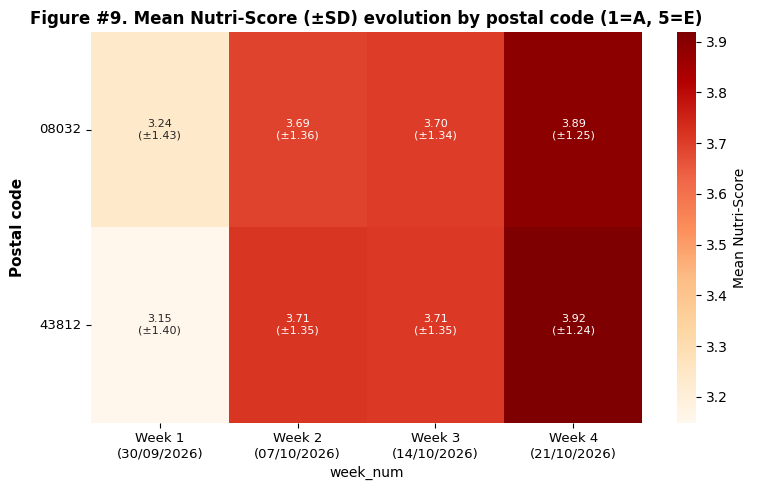

In [53]:
plot_heatmap_week_nutri_score(df_products, week_label_map)

TODO: Treure conclusions quan tingui totes les dades.

In [54]:
def plot_heatmap_week_ewo_ultraprocessing_level(df_products: pd.DataFrame, week_label_map: dict) -> None:
    """
    Function that plots information about how change Ewö ultraprocessing level per week using mean and SD.

    Args:
        df_products (pd.DataFrame): DataFrame with the products.
        week_label_map (dict): Dictionary with label information.

    Returns:
        None. Plots the heatmap.
    """

    p_ewo_mean, p_ewo_annot = get_mean_std_pivots(df_products, 'ewo_ultra_processed_punctuation', week_label_map)

    plot_temporal_heatmap(
        p_ewo_mean,
        p_ewo_annot, 
        'OrRd',
        'Mean Ewö ultraprocessing level',
        'Figure #10. Mean Ewö ultraprocessing level (±SD) evolution by postal code (from 1 - minimum to 4 - ultraprocessed)'
    )

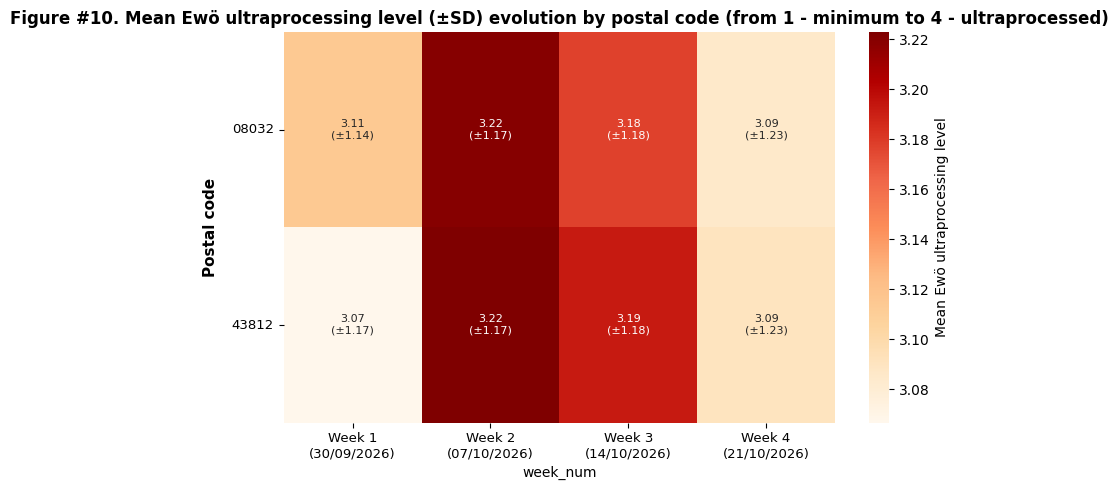

In [55]:
plot_heatmap_week_ewo_ultraprocessing_level(df_products, week_label_map)

TODO: Treure'n conclusions quan tingui totes les dades.

In [56]:
def plot_heatmap_week_planet_score(df_products: pd.DataFrame, week_label_map: dict) -> None:
    """
    Function that plots information about how change Planet-Score per week using mean and SD.

    Args:
        df_products (pd.DataFrame): DataFrame with the products.
        week_label_map (dict): Dictionary with label information.

    Returns:
        None. Plots the heatmap.
    """

    p_planet_mean, p_planet_annot = get_mean_std_pivots(df_products, 'planetscore_num', week_label_map)

    plot_temporal_heatmap(
        p_planet_mean,
        p_planet_annot, 
        'OrRd',
        'Mean Planet-Score',
        'Figure #11. Mean Planet-Score (±SD) evolution by postal code (1=A, 5=E)'
    )

In [57]:
#plot_heatmap_week_planet_score(df_products, week_label_map)

TODO: Treure'n conclusions quan tingui totes les dades.

### 3.3.3. Information about homepage sections

In [58]:
def generate_homepage_sections_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Function that generates information of homepage sections per week.
    It shows the total products every week and how changes Nutri-Score,
    Ewö ultraprocessing level and Planet-Score.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        pd.DataFrame: DataFrame with the data for every week and homepage section.
    """

    has_planet_data = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )

    df_home = df[df['title_category_main_page'].notna()].copy()

    rows = []
    grouped = df_home.groupby(['title_category_main_page', 'week_num'], observed=True)

    for (section, week), group in grouped:
        n_products = len(group)

        nutri_s = group['nutriscore_num'].dropna()
        nutri_str = (
            f'{nutri_s.mean():.2f} ({nutri_s.std():.2f})'
            if len(nutri_s) > 1
            else (f'{nutri_s.mean():.2f}' if len(nutri_s) == 1 else 'N/A')
        )

        ewo_s = group['ewo_ultra_processed_punctuation'].dropna()
        ewo_str = (
            f'{ewo_s.mean():.2f} ({ewo_s.std():.2f})'
            if len(ewo_s) > 1
            else (f'{ewo_s.mean():.2f}' if len(ewo_s) == 1 else 'N/A')
        )

        if has_planet_data:
            planet_s = group['planetscore_num'].dropna()
            planet_str = (
                f'{planet_s.mean():.2f} ({planet_s.std():.2f})'
                if len(planet_s) > 1
                else (f'{planet_s.mean():.2f}' if len(planet_s) == 1 else 'N/A')
            )
        else:
            planet_str = 'Pending'

        rows.append({
            'Homepage Sections': section,
            'Week': week,
            'Number of products': n_products,
            'Nutri-Score (Mean, SD)': nutri_str,
            'Ewö (Mean, SD)': ewo_str,
            'Planet-Score (Mean, SD)': planet_str,
        })

    return pd.DataFrame(rows)

In [59]:
homepage_table_df = generate_homepage_sections_table(df_products)

print("Table #14. Weekly distribution of product volume and mean health & environmental scores (Nutri-Score, Ewö, Planet-Score)\
 across featured homepage sections")
homepage_table_df

Table #14. Weekly distribution of product volume and mean health & environmental scores (Nutri-Score, Ewö, Planet-Score) across featured homepage sections


,Homepage Sections,Week,Number of products,"Nutri-Score (Mean, SD)","Ewö (Mean, SD)","Planet-Score (Mean, SD)"
0,Bajadas de precio,40,227,3.55 (1.15),3.41 (0.97),Pending
1,Bajadas de precio,41,248,3.14 (1.29),3.25 (1.06),Pending
2,Bajadas de precio,42,234,3.12 (1.26),3.19 (1.10),Pending
3,Bajadas de precio,43,197,3.47 (1.19),3.16 (1.12),Pending
4,Disfruta La Castañada,43,16,3.25 (1.39),2.50 (1.31),Pending
5,Han vuelto,40,42,4.04 (1.34),2.57 (1.42),Pending
6,Han vuelto,41,71,4.08 (1.23),3.00 (1.31),Pending
7,Han vuelto,42,58,4.29 (1.13),3.10 (1.27),Pending
8,Han vuelto,43,70,4.24 (1.13),2.93 (1.29),Pending
9,Novedades,40,68,3.97 (1.21),3.45 (1.08),Pending


## 3.4. Product characteristics by healthiness and environmental sustainability in homepage categories

In [60]:
def generate_healthiness_sustainability_homepage_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Function that generates the health and environmental sustainability feature table,
    grouped by the Homepage Sections.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        pd.DataFrame: DataFrame with results.
    """

    has_planet = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )

    df_home = df[df['title_category_main_page'].notna()].copy()

    rows = []

    for section_name, group in df_home.groupby('title_category_main_page', observed=True):
        n_products = len(group)
        nutri_s = group['nutriscore_num'].dropna()
        nutri_str = (
            f'{nutri_s.mean():.2f} ({nutri_s.std():.2f})'
            if len(nutri_s) > 1
            else (f'{nutri_s.mean():.2f}' if len(nutri_s) == 1 else 'N/A')
        )

        ewo_s = group['ewo_ultra_processed_punctuation'].dropna()
        ewo_str = (
            f'{ewo_s.mean():.2f} ({ewo_s.std():.2f})'
            if len(ewo_s) > 1
            else (f'{ewo_s.mean():.2f}' if len(ewo_s) == 1 else 'N/A')
        )

        if has_planet:
            planet_s = group['planetscore_num'].dropna()
            planet_str = (
                f'{planet_s.mean():.2f} ({planet_s.std():.2f})'
                if len(planet_s) > 1
                else (f'{planet_s.mean():.2f}' if len(planet_s) == 1 else 'N/A')
            )
        else:
            planet_str = 'Pending'

        rows.append({
            'Homepage Section': section_name,
            'Homepage (n)': n_products,
            'Nutri-Score (Mean; SD)': nutri_str,
            'Ewö (Mean; SD)': ewo_str,
            'Planet-Score (Mean; SD)': planet_str,
        })

    total_n = len(df_home)
    nutri_tot = df_home['nutriscore_num'].dropna()
    ewo_tot = df_home['ewo_ultra_processed_punctuation'].dropna()

    nutri_tot_str = (
        f'{nutri_tot.mean():.2f} ({nutri_tot.std():.2f})'
        if len(nutri_tot) > 1
        else 'N/A'
    )
    ewo_tot_str = (
        f'{ewo_tot.mean():.2f} ({ewo_tot.std():.2f})'
        if len(ewo_tot) > 1
        else 'N/A'
    )

    if has_planet:
        planet_tot = df_home['planetscore_num'].dropna()
        planet_tot_str = (
            f'{planet_tot.mean():.2f} ({planet_tot.std():.2f})'
            if len(planet_tot) > 1
            else 'N/A'
        )
    else:
        planet_tot_str = 'Pending'

    rows.append({
        'Homepage Section': 'TOTAL HOMEPAGE',
        'Homepage (n)': total_n,
        'Nutri-Score (Mean; SD)': nutri_tot_str,
        'Ewö (Mean; SD)': ewo_tot_str,
        'Planet-Score (Mean; SD)': planet_tot_str,
    })

    return pd.DataFrame(rows)

In [61]:
health_sustainability_homepage_df = generate_healthiness_sustainability_homepage_table(df_products)

print("Table #15. Aggregate sample sizes and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score)\
 across Homepage Sections.")
health_sustainability_homepage_df

Table #15. Aggregate sample sizes and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score) across Homepage Sections.


,Homepage Section,Homepage (n),Nutri-Score (Mean; SD),Ewö (Mean; SD),Planet-Score (Mean; SD)
0,Bajadas de precio,906,3.30 (1.24),3.26 (1.07),Pending
1,Disfruta La Castañada,16,3.25 (1.39),2.50 (1.31),Pending
2,Han vuelto,241,4.17 (1.19),2.93 (1.32),Pending
3,Novedades,329,3.90 (1.32),3.20 (1.23),Pending
4,Productos del momento,331,3.71 (1.60),3.03 (1.24),Pending
5,TOTAL HOMEPAGE,1823,3.61 (1.37),3.15 (1.18),Pending


## 3.5. Contraposition of target variables

In [62]:
def add_jitter(series: pd.core.series.Series, amount:float = 0.15) -> pd.core.series.Series:
    """
    Function that add jitter in the values to not concentrate all dots in the same point.

    Args:
        series (pd.core.series.Series): Data.
        amount (float): Quantity of jitter.

    Returns:
        pd.core.series.Series: The new series with the added jitter.
    """

    return series + np.random.uniform(-amount, amount, size=len(series))

def plot_cross_indicator_scatters(
    df: pd.DataFrame,
    variable_1: str,
    variable_2: str,
    title_text: str,
    x_label: str,
    y_label: str,
    x_ticks: list,
    x_tick_labels: list,
    y_ticks: list,
    y_tick_labels: list = None,
    hue_col: str = None
) -> None:
    """
    Function that generates an scatter plot crossing two variables.
    by using jitter and continous colour gradient based on the
    variable percentage_discount.

    Args:
        df (pd.DataFrame): DataFrame with data.
        variable_1 (str): First variable name to use.
        variable_2 (str): Second variable name to use.
        title_text (str): Title of the graphic.
        x_label (str): Label to use on x axis.
        y_label (str): Label to use on y axis.
        x_ticks (list): List of labels for x axis.
        x_tick_labels (list): Tick labels for x axis.
        y_ticks (list): List of y axis ticks.
        y_tick_labels (list): List of y tick labels.

    Returns:
        None. Prints out the graphic.    
    """

    plt.figure(figsize=(8, 6))

    if hue_col is not None:
        sns.scatterplot(
            x=add_jitter(df[variable_1]),
            y=add_jitter(df[variable_2]),
            hue=df[hue_col],
            alpha=0.5,
            s=35,
            palette='Set1' if hue_col else None
        )
    else:
        sns.scatterplot(
            x=add_jitter(df[variable_1]),
            y=add_jitter(df[variable_2]),
            hue=df['percentage_discount'],
            palette='YlOrRd',
            alpha=0.6,
            s=40,
        )

    plt.title(title_text, fontweight='bold', fontsize=12)
    plt.xlabel(x_label, fontsize=11, fontweight='bold', labelpad=10)
    plt.ylabel(y_label, fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(x_ticks, x_tick_labels, rotation=0, ha='center', fontsize=9.5)

    if y_tick_labels:
        plt.yticks(y_ticks, y_tick_labels, rotation=0, fontsize=9.5)
    else:
        plt.yticks(y_ticks, rotation=0, fontsize=9.5)

    plt.grid(True, linestyle='--', alpha=0.4)
    plt.legend(
        title=hue_col if hue_col is not None else '% Discount',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        frameon=True,
    )

    plt.tight_layout()
    plt.show()

In [63]:
def plot_nutriscore_vs_ewo(df: pd.DataFrame, hue_col: str = None) -> None:
    """
    Function to generate the comparative between Nutri-Score and Ewö ultraprocessing level.

    Args:
        df (pd.DataFrame): DataFrame with data.
        hue_col (str): Variable to determine hue. By default, None.

    Returns:
        None. Prints out the graphic.
    """
    
    data_filtered = df.dropna(
        subset=['nutriscore_num', 'ewo_ultra_processed_punctuation']
    )

    plot_cross_indicator_scatters(
        df=data_filtered,
        variable_1='nutriscore_num',
        variable_2='ewo_ultra_processed_punctuation',
        title_text='Figure #12. Nutri-Score vs. Ewö Ultraprocessing Level',
        x_label='Nutri-Score (1=A, 5=E)',
        y_label='EWÖ Ultraprocessing Level (1=Minimum, 4=Ultraprocessed)',
        x_ticks=[1, 2, 3, 4, 5],
        x_tick_labels=['A', 'B', 'C', 'D', 'E'],
        y_ticks=[1, 2, 3, 4],
        hue_col=hue_col
    )

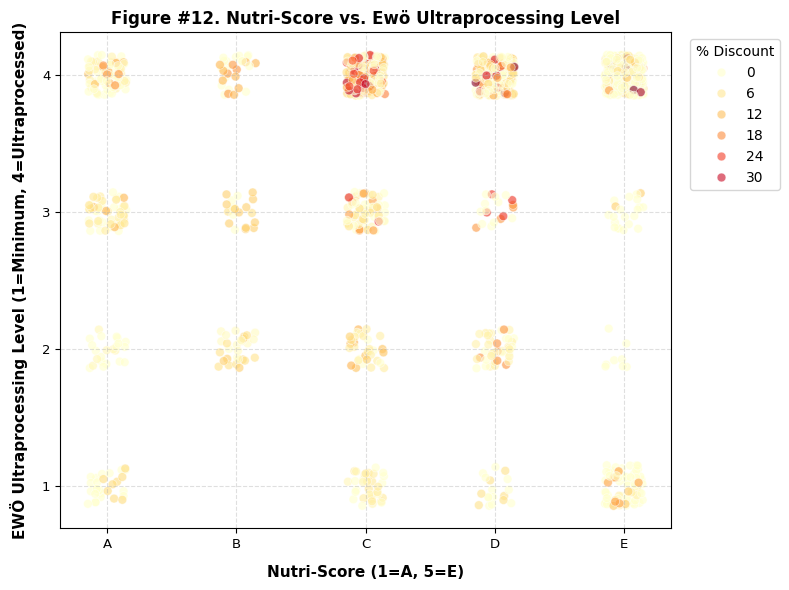

In [64]:
plot_nutriscore_vs_ewo(df_products)

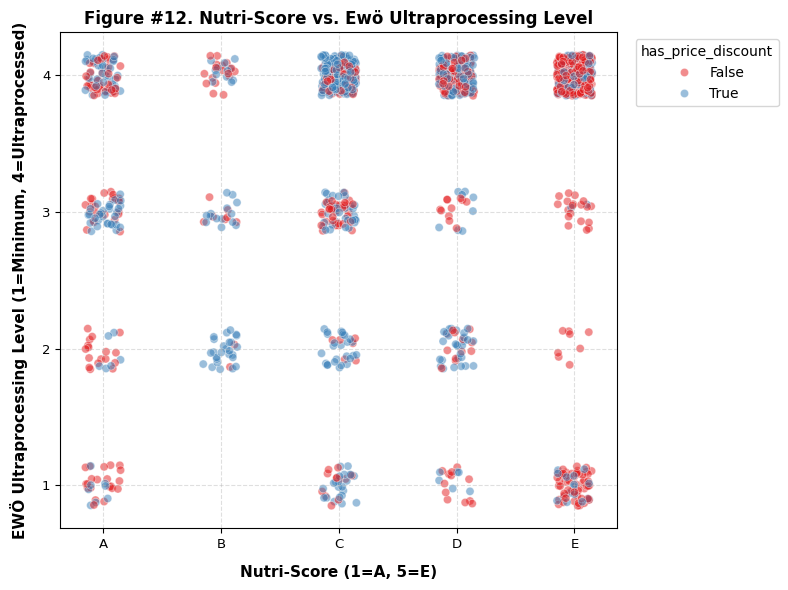

In [65]:
plot_nutriscore_vs_ewo(df_products,'has_price_discount')

TODO: Quan tigui totes les dades ja treuré les conclusions pertinents.

In [66]:
def plot_nutriscore_vs_planet_score(df: pd.DataFrame) -> None:
    """
    Function to generate the comparative between Nutri-Score and Planet-Score.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints out the graphic.
    """

    data_filtered = df.dropna(subset=['nutriscore_num', 'planetscore_num'])

    plot_cross_indicator_scatters(
        df = data_filtered,
        variable_1='nutriscore_num',
        variable_2='planetscore_num',
        title_text='Figure #13. Nutri-Score vs. Planet-Score',
        x_label='Nutri-Score (1=A, 5=E)',
        y_label='Planet-Score (1=A, 5=E)',
        x_ticks=[1, 2, 3, 4, 5],
        x_tick_labels=['A', 'B', 'C', 'D', 'E'],
        y_ticks=[1, 2, 3, 4, 5],
        y_tick_labels=['A', 'B', 'C', 'D', 'E']
    )

In [67]:
# plot_nutriscore_vs_planet_score(df_products)

TODO: Quan tigui totes les dades ja treuré les conclusions pertinents.

In [68]:
def plot_planet_score_vs_ewo_ultraprocessing_level(df: pd.DataFrame) -> None:
    """
    Function to generate the comparative between Planet-Score and Ewö ultraprocessing level.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints out the graphic.
    """

    data_filtered = df.dropna(subset=['planetscore_num', 'ewo_ultra_processed_punctuation'])

    plot_cross_indicator_scatters(
        df = data_filtered,
        variable_1='planetscore_num',
        variable_2='ewo_ultra_processed_punctuation',
        title_text='Figure #14. Planet-Score vs. EWÖ',
        x_label='Planet-Score (1=A, 5=E)',
        y_label='Ewö ultraprocessing level (1=Minimum, 4=Ultraprocessing)',
        x_ticks=[1, 2, 3, 4, 5],
        x_tick_labels=['A', 'B', 'C', 'D', 'E'],
        y_ticks=[1, 2, 3, 4]
    )

In [69]:
# plot_planet_score_vs_ewo_ultraprocessing_level(df_products)

TODO: Quan tigui totes les dades ja treuré les conclusions pertinents.

# 4. Hypothesis test

## 4.1. Nutri-Score

### 4.1.1. Test 1: The proportion of promotion products is significantly major on unhealthy products (Nutri-Score D/E) in comparison on healthy products (Nutri-Score A/B)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \hat{p}_{1} = \hat{p}_{2} \\
H_{1}: \hat{p}_{1} > \hat{p}_{2}
\end{align*}
$$

$$
\begin{align*}
\hat{p}_{1}:\ Proportion\ of \ unhealthy\ products\ (Nutri-Score\ D/E) \\
\hat{p}_{2}:\ Proportion\ of \ healthy\ products\ (Nutri-Score\ A/B)
\end{align*}
$$

#### Selection of the data

In [70]:
df_selected_rows = df_products[
    df_products['nutriscore'].isin(['A', 'B', 'D', 'E'])
].copy()

df_selected_rows['quality_group'] = df_selected_rows['nutriscore'].apply(
    lambda x: 'A/B' if x in ['A', 'B'] else 'D/E'
)

group_ab = df_selected_rows[df_selected_rows['quality_group'] == 'A/B']
group_de = df_selected_rows[df_selected_rows['quality_group'] == 'D/E']

#### Presentation of the samples and determine statistical test

En primer lloc i d’acord amb el Teorema del límit central, que ens diu:

Sigui X una variable aleatòria amb una distribució binomial de paràmetres n i p. Si n és gran, aleshores la distribució de X és aproximadament normal amb esperança np i variància np(1-p). A la pràctica s’acostuma a utilitzar aquesta aproximació quan np i n(1-p) són tots dos més grans que 5, o bé quan n > 30.

Hem de verificar que estem davant d’una binomial. D’acord amb la transformació que hem fet i sabent que una distribució binomial només pot prendre valors 1 o 0, podem afirmar que ens trobem davant d’una binomial. Així doncs, només ens queda comprovar si les dades es poden considerar prou grans.

Per tal de dur a terme aquesta comprovació, hem de calcular per cada grup

$$
\begin{align*}
\mu=n\hat{p} \\
\sigma^2=n(1−\hat{p}) \\
Amb\ \mu\ i\ \sigma^2>5
\end{align*}
$$

In [71]:
contingency_table = pd.crosstab(
    df_selected_rows['quality_group'], df_selected_rows['is_promoted']
)

n_promoted_de = contingency_table.loc['D/E', True]
n_total_de = contingency_table.loc['D/E'].sum()

n_promoted_ab = contingency_table.loc['A/B', True]
n_total_ab = contingency_table.loc['A/B'].sum()

p_hat_de = n_promoted_de / n_total_de
p_hat_ab = n_promoted_ab / n_total_ab

print(f"Group A/B: n={n_total_ab}, p={p_hat_ab}\nGroup D/E: n={n_total_de}, p={p_hat_de}")

Group A/B: n=264, p=0.5151515151515151
Group D/E: n=801, p=0.38701622971285893


In [72]:
mu_ab = n_total_ab*p_hat_ab
sigma_ab = n_total_ab*(1-p_hat_ab)

mu_de = n_total_de*p_hat_de
sigma_de = n_total_de*(1-p_hat_de)

print(f"\u03BC_ab={mu_ab}, \u03C3^2_ab={sigma_ab}\n\u03BC_de={mu_de}, \u03C3^2_de={sigma_de}")

μ_ab=136.0, σ^2_ab=128.0
μ_de=310.0, σ^2_de=490.99999999999994


D’acord amb la teoria, podem arribar a determinar que les dades podrien arribar a considerar-se prou grans. Així doncs, faré el test de proporcions *z* unilateral per la dreta, el qual segueix la l'expressió:

$$
z=\frac{(\hat{p}_1-\hat{p}_2)}{\sqrt{p(1-p)(\frac{1}{n_1}+\frac{1}{n_2})}} \sim N(0,1)
$$

Essent *p* un paràmetre desconegut, del qual s'en fa una estimació $\hat{p}$ a partir de les mostres:

$$
\hat{p}=\frac{n_1\hat{p}_1+n_2\hat{p}_2}{n_1+n_2}
$$

#### Applying test and check hypothesis

In [73]:
count = [n_promoted_de, n_promoted_ab]
nobs = [n_total_de, n_total_ab]

z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

if p_value < ALPHA:
    print("Descartem H0. Per tant, La proporció de productes promocionats és significativament major en D/E que en A/B.")
else:
    print(
        'No es pot rebutjar H0: No hi ha evidència suficient per afirmar que'
        ' D/E té més promocions que A/B.'
    )

No es pot rebutjar H0: No hi ha evidència suficient per afirmar que D/E té més promocions que A/B.


### 4.1.2. Test 2: When a price discount is applied, is the mean percentage reduction on unhealthy products (D/E) greater than on healthy ones (A/B)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1} = \mu_{2} \\
H_{1}: \mu_{1} > \mu_{2}
\end{align*}
$$

$$
\begin{align*}
\mu_{1}:\ Unhealthy\ products\ percentage\ (Nutri-Score\ D/E) \\
\mu_{2}:\ Healthy\ products\ percentage\ (Nutri-Score\ A/B)
\end{align*}
$$

#### Selection of the data

In [74]:
products_with_percentage_discount = df_products[df_products["has_price_discount"] == True]

df_unique_promo = (
    products_with_percentage_discount.groupby('id_product')
    .agg({
        'nutriscore': 'first',
        'percentage_discount': 'mean',
    })
    .reset_index()
)

df_unique_promo = df_unique_promo[
    df_unique_promo['nutriscore'].isin(['A', 'B', 'D', 'E'])
].copy()

df_unique_promo['quality_group'] = df_unique_promo['nutriscore'].apply(
    lambda x: 'A/B' if x in ['A', 'B'] else 'D/E'
)

group_ab = df_unique_promo[df_unique_promo['quality_group'] == 'A/B']['percentage_discount']
group_de = df_unique_promo[df_unique_promo['quality_group'] == 'D/E']['percentage_discount']

#### Presentation of the samples and determine statistical test

REVISAR, PERQUE ARA HO HE HAGUT DE CANVIAR PERQ NO ARRIBA A 30 EL VALOR DEL GRUP A/B!!!!!!!!!!!!!!!!!!!!!!!

In [75]:
n_ab, mean_ab, std_ab = len(group_ab), group_ab.mean(), group_ab.std()
n_de, mean_de, std_de = len(group_de), group_de.mean(), group_de.std()

print(f'Group A/B (Healthy): n = {n_ab}, mean = {mean_ab:.2f}%, sd = {std_ab:.2f}%')
print(f'Group D/E (Unhealthy): n = {n_de}, mean = {mean_de:.2f}%, sd = {std_de:.2f}%')

Group A/B (Healthy): n = 28, mean = 7.80%, sd = 5.09%
Group D/E (Unhealthy): n = 68, mean = 12.42%, sd = 8.54%


Com que tenim un grup que n <= 30, pel teorema del límit central no podem determinar que les variables siguin normals. Per tal de verificar-ho, aplicarem el test de Shapiro-Wilk.

In [76]:
shapiro_ab_stat, shapiro_ab_p = stats.shapiro(group_ab)
shapiro_de_stat, shapiro_de_p = stats.shapiro(group_de)


if shapiro_ab_p < ALPHA or shapiro_de_p < ALPHA:
    print(' -> Almenys un grup NO és normal (p < 0.05). Cal utilitzar un test NO PARAMÈTRIC (Mann-Whitney U).')
else:
    print(' -> Ambdós grups SÓN NORMALS (p >= 0.05). Procedim amb el test paramètric (Test t).')

 -> Almenys un grup NO és normal (p < 0.05). Cal utilitzar un test NO PARAMÈTRIC (Mann-Whitney U).


En aquest cas, tot i que no s'assumeix que les poblacions siguin normals, s'assumeix que la distribució de les poblacions és la mateixa, la qual cosa implica varància igual. Donada aquesta assumpció, el test es pot aplicar sobre les medianes i també, sobre les mitjanes, que és el nostre cas. De forma matemàtica, el que es fa és combinar totes les observacions $N=n_1+n_2$, ordenant-les de major a menor assignant-los-hi un rang $R_i$ (de $1$ a $N$, aplicant el rang mitjà en cas d'empats). Es calcula la suma de rangs $R_1$ per al primer grup i $R_2$ pel segon, i apareixen aquestes fòrmules:

$$
U_1=R_1- \frac{n_1(n_1+1)}{2}
$$

$$
U_2=R_2 - \frac{n_2(n_2+1)}{2}
$$

On $n_1$ i $n_2$ són les mides mostrals dels grups D/E i A/B respectivament. L'estadístic utilitzat per al contrast unilateral per la dreta és $U = U_1$.

El valor estadístic és el mínim dels dos: $U=min(U_1, U_2)$.

#### Applying test and check hypothesis

In [77]:
u_stat, p_val = stats.mannwhitneyu(group_de, group_ab, alternative='greater')

if p_val < ALPHA:
    print("Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
else:
    print("No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


### 4.1.3. Test 3: When a price discount is applied, are there significant differences in the average discount percentage between promoted products with Nutri-Score D/E in comparison with Nutri-Score A/B, stratified by postal code?


REVISAAAAAAAAAAAAAAAAAAAAAAAR PERQUE EM PASSARÀ EL MATEIX QUE EN EL CAS ANTERIOR, QUE NO ARRIBA A 30, DE MOMENT HO DEIXO AIXI (EL TEST ESTADÍSTIC) PERÒ SI AL FINAL NO ARRIBO, HE D'APLICAR TEST D'U AQUEST.

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1,k} = \mu_{2,k} \\
H_{1}: \mu_{1,k} > \mu_{2,k} \\
k \in \{43812, 08032\}
\end{align*}
$$

$$
\begin{align*}
\mu_{1,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ unhealthy\ (Nutri-Score\ D/E)\ in\ postal\ code\ k \\
\mu_{2,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ healthy\ (Nutri-Score\ A/B)\ in\ postal\ code\ k \\
\end{align*}
$$

#### Selection of the data

In [78]:
postal_codes = sorted(products_with_percentage_discount['postal_code'].dropna().unique())

pc_data = {}

for pc in postal_codes:
    df_pc = products_with_percentage_discount[products_with_percentage_discount['postal_code'] == pc].copy()
    df_pc_unique = (
            df_pc.groupby('id_product')
            .agg({'nutriscore': 'first', 'percentage_discount': 'mean'})
            .reset_index()
        )

    df_pc_selected = df_pc_unique[
        df_pc_unique['nutriscore'].isin(['A', 'B', 'D', 'E'])
    ].copy()
    df_pc_selected['quality_group'] = df_pc_selected['nutriscore'].apply(
        lambda x: 'A/B' if x in ['A', 'B'] else 'D/E'
    )

    group_abc = df_pc_selected[df_pc_selected['quality_group'] == 'A/B']['percentage_discount'].dropna()
    group_de = df_pc_selected[df_pc_selected['quality_group'] == 'D/E']['percentage_discount'].dropna()
    
    pc_data[int(pc)] = {'group_abc': group_abc, 'group_de': group_de }

#### Presentation of the samples and determine statistical test

In [79]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']

    n_abc, mean_abc, std_abc = (len(group_abc),group_abc.mean(),group_abc.std())
    n_de, mean_de, std_de = (len(group_de), group_de.mean(), group_de.std())
    
    print(f"Postal code {pc}:\n Group healthy (A/B) n={n_abc}, mean={mean_abc}%, sd={std_abc}%\n Group unhealthy (D/E) n={n_de}, mean={mean_de}%, sd={std_de}")

Postal code 8032:
 Group healthy (A/B) n=28, mean=7.795178571428571%, sd=5.0869883912642395%
 Group unhealthy (D/E) n=68, mean=12.423970588235292%, sd=8.537795713233779
Postal code 43812:
 Group healthy (A/B) n=28, mean=7.795178571428571%, sd=5.0869883912642395%
 Group unhealthy (D/E) n=68, mean=12.423970588235292%, sd=8.537795713233779


--------PER PROVAR LA U AQUESTA-----------

**AQUI ES ON BAIXA A < 30... PER TANT, AQUI PASSA EL MATEIX QUE EL CAS ANTERIOR, ARA, NO SE DESPRES D'AQUESTA SETMANA, per això ho deixo així de moment, perquè potser arribo aquesta setmana o la que ve**

In [80]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']
    shapiro_ab_stat, shapiro_ab_p = stats.shapiro(group_ab)
    shapiro_de_stat, shapiro_de_p = stats.shapiro(group_de)

    if shapiro_ab_p < ALPHA or shapiro_de_p < ALPHA:
        print(f' {pc} -> Almenys un grup NO és normal (p < 0.05). Cal utilitzar un test NO PARAMÈTRIC (Mann-Whitney U).')
    else:
        print(f' {pc} -> Ambdós grups SÓN NORMALS (p >= 0.05). Procedim amb el test paramètric (Test t).')

for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']

    u_stat, p_val = stats.mannwhitneyu(group_de, group_ab, alternative='greater')

    if p_val < ALPHA:
        print(f"{pc} - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
    else:
        print(f"{pc} - No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")


 8032 -> Almenys un grup NO és normal (p < 0.05). Cal utilitzar un test NO PARAMÈTRIC (Mann-Whitney U).
 43812 -> Almenys un grup NO és normal (p < 0.05). Cal utilitzar un test NO PARAMÈTRIC (Mann-Whitney U).
8032 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.
43812 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


--------FINS AQUI LO DE LA U DE MAHATTAN AQUESTA----------

Pel teorema del límit central, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [81]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']

    levene_stats, levene_p = stats.levene(group_de, group_abc)
    if levene_p < ALPHA:
        print(f"{pc} - Descartem H0. Les variancies no son iguals.")
    else:
        print(f"{pc} - No podem descartar H0. Les variances son iguals.")

8032 - Descartem H0. Les variancies no son iguals.
43812 - Descartem H0. Les variancies no son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies diferents (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x_{1}} - \bar{x_{2}}}{\sqrt{\frac{s^2_{1}}{n_1}+\frac{s^2_2}{n_2}}} \sim t_{v}
$$

I té *v* graus de llibertat:

$$
v=\frac{(\frac{s^2_1}{n_1}+\frac{s^2_{2}}{n_2})^2}{\frac{(\frac{s^2_{1}}{n_1})^2}{(n_{1}-1)} + \frac{(\frac{s^2_{2}}{n_{2}})^2}{(n_2-1)}}
$$

#### Applying test and check hypothesis

In [82]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']
    t_stat, p_val = stats.ttest_ind(
        group_de,
        group_ab,
        equal_var=False,
        alternative="greater"
    )
    
    if p_val < ALPHA:
        print(f"{pc} - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
    else:
        print(f"{pc} - No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

8032 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.
43812 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


## 4.2. Ultraprocessing level by Ewö algorithm

FER NOMÉS EL PRIMER TEST PQ JA ES VEU QUE ES REDUNDANT MIRAR-HO PER CODI POSTAL PQ LI PASSA EL MATEIX A LES PROMOCIONS en els dos codis postals, explicar-ho bé

### 4.2.1. Test 1: The proportion of promotion products is significantly major on processed/ultraprocessed products (3/4) in comparison of healthy products (1/2)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \hat{p}_{1} = \hat{p}_{2} \\
H_{1}: \hat{p}_{1} > \hat{p}_{2}
\end{align*}
$$

$$
\begin{align*}
\hat{p}_{1}:\ Proportion\ of \ processed/ultraprocessed\ products\ (Ewö\ 3/4) \\
\hat{p}_{2}:\ Proportion\ of \ low/medium\ processed\ products\ (Ewö\ 1/2)
\end{align*}
$$

#### Selection of the data

In [83]:
df_selected_rows = df_products[
    df_products['ewo_ultra_processed_punctuation'].isin([1.0, 2.0, 3.0, 4.0])
].copy()

df_selected_rows['quality_group'] = df_selected_rows['ewo_ultra_processed_punctuation'].apply(
    lambda x: '1/2' if x in [1.0, 2.0] else '3/4'
)

group_low = df_selected_rows[df_selected_rows['quality_group'] == '1/2']
group_high = df_selected_rows[df_selected_rows['quality_group'] == '3/4']

#### Presentation of the samples and determine statistical test

En primer lloc i d’acord amb el Teorema del límit central, que ens diu:

Sigui X una variable aleatòria amb una distribució binomial de paràmetres n i p. Si n és gran, aleshores la distribució de X és aproximadament normal amb esperança np i variància np(1-p). A la pràctica s’acostuma a utilitzar aquesta aproximació quan np i n(1-p) són tots dos més grans que 5, o bé quan n > 30.

Hem de verificar que estem davant d’una binomial. D’acord amb la transformació que hem fet i sabent que una distribució binomial només pot prendre valors 1 o 0, podem afirmar que ens trobem davant d’una binomial. Així doncs, només ens queda comprovar si les dades es poden considerar prou grans.

Per tal de dur a terme aquesta comprovació, hem de calcular per cada grup

$$
\begin{align*}
\mu=n\hat{p} \\
\sigma^2=n(1−\hat{p}) \\
Amb\ \mu\ i\ \sigma^2>5
\end{align*}
$$

In [84]:
contingency_table = pd.crosstab(
    df_selected_rows['quality_group'], df_selected_rows['is_promoted']
)


n_promoted_high = contingency_table.loc['3/4', True]
n_total_high = contingency_table.loc['3/4'].sum()

n_promoted_low = contingency_table.loc['1/2', True]
n_total_low = contingency_table.loc['1/2'].sum()

p_hat_high = n_promoted_high / n_total_high
p_hat_low = n_promoted_low / n_total_low

print(f"Group low processed: n={n_total_low}, p={p_hat_low}\n\
Group processed/ultraprocessed: n={n_total_high}, p={p_hat_high}")

Group low processed: n=440, p=0.43636363636363634
Group processed/ultraprocessed: n=1200, p=0.49


In [85]:
mu_low = n_total_low*p_hat_low
sigma_low = n_total_low*(1-p_hat_low)

mu_high = n_total_high*p_hat_high
sigma_high = n_total_high*(1-p_hat_high)

print(f"\u03BC_low={mu_low}, \u03C3^2_low={sigma_low}\n\u03BC_high={mu_high}, \u03C3^2_high={sigma_high}")

μ_low=192.0, σ^2_low=248.00000000000003
μ_high=588.0, σ^2_high=612.0


D’acord amb la teoria, podem arribar a determinar que les dades podrien arribar a considerar-se prou grans. Així doncs, faré el test de proporcions *z* unilateral per la dreta, el qual segueix la l'expressió:

$$
z=\frac{(\hat{p}_1-\hat{p}_2)}{\sqrt{p(1-p)(\frac{1}{n_1}+\frac{1}{n_2})}} \sim N(0,1)
$$

Essent *p* un paràmetre desconegut, del qual s'en fa una estimació $\hat{p}$ a partir de les mostres:

$$
\hat{p}=\frac{n_1\hat{p}_1+n_2\hat{p}_2}{n_1+n_2}
$$

#### Applying test and check hypothesis

In [86]:
count = [n_promoted_high, n_promoted_low]
nobs = [n_total_high, n_total_low]

z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

if p_value < ALPHA:
    print("Descartem H0. Per tant, La proporció de productes promocionats és significativament major en processats i ultraprocessats (3/4) que en poc processats (1/2).")
else:
    print(
        'No es pot rebutjar H0: No hi ha evidència suficient per afirmar que'
        ' 3/4 té més promocions que 1/2.'
    )

Descartem H0. Per tant, La proporció de productes promocionats és significativament major en processats i ultraprocessats (3/4) que en poc processats (1/2).


### 4.2.2. Test 2: When a price discount is applied, is the mean percentage reduction on processed and high-processed (3/4) greater than on low and medium processed (1/2)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1} = \mu_{2} \\
H_{1}: \mu_{1} > \mu_{2}
\end{align*}
$$

$$
\begin{align*}
\mu_{1}:\ Unhealthy\ products\ percentage\ (Ewö\ 3/4) \\
\mu_{2}:\ Healthy\ products\ percentage\ (Ewö\ 1/2)
\end{align*}
$$

#### Selection of the data

In [87]:
products_with_percentage_discount = df_products[df_products["has_price_discount"] == True]

df_unique_promo = (
    products_with_percentage_discount.groupby('id_product')
    .agg({
        'product_name': 'first',
        'ewo_ultra_processed_punctuation': 'first',
        'percentage_discount': 'mean',  # Descompte mitjà del producte quan s'ha promocionat
    })
    .reset_index()
)

df_unique_promo = df_unique_promo[
    df_unique_promo['ewo_ultra_processed_punctuation'].isin([1.0, 2.0, 3.0, 4.0])
].copy()

df_unique_promo['quality_group'] = df_unique_promo['ewo_ultra_processed_punctuation'].apply(
    lambda x: '1/2' if x in [1.0, 2.0] else '3/4'
)

group_low_medium_processing = df_unique_promo[df_unique_promo['quality_group'] == '1/2']['percentage_discount']
group_high_ultra_processing = df_unique_promo[df_unique_promo['quality_group'] == '3/4']['percentage_discount']

#### Presentation of the samples and determine statistical test

REVISAR, PERQUE ARA HO HE HAGUT DE CANVIAR PERQ NO ARRIBA A 30 EL VALOR DEL GRUP A/B!!!!!!!!!!!!!!!!!!!!!!!

In [88]:
n_low_medium_processing, mean_low_medium_processing, std_low_medium_processing = len(group_low_medium_processing), group_low_medium_processing.mean(), group_low_medium_processing.std()
n_high_ultra_processing, mean_high_ultra_processing, std_high_ultra_processing = len(group_high_ultra_processing), group_high_ultra_processing.mean(), group_high_ultra_processing.std()

print(f'Group A/B (Healthy): n = {n_low_medium_processing}, mean = {mean_low_medium_processing:.2f}%, sd = {std_low_medium_processing:.2f}%')
print(f'Group D/E (Unhealthy): n = {n_high_ultra_processing}, mean = {mean_high_ultra_processing:.2f}%, sd = {std_high_ultra_processing:.2f}%')

Group A/B (Healthy): n = 33, mean = 7.40%, sd = 4.62%
Group D/E (Unhealthy): n = 132, mean = 11.88%, sd = 8.23%


**Teorema del límit central**

El teorema del límit central diu que si una mostra és prou gran (n > 30), sigui quina sigui la distribució de la variable d'interès, la distribució de la mitjana mostral serà aproximadament una normal. A més, la mitjana serà la mateixa que la de la variable d'interès, i la desviació típica de la mitjana mostral serà aproximadament l'error estàndard.


Com que tenim un grup que n <= 30, pel teorema del límit central no podem determinar que les variables siguin normals. Per tal de verificar-ho, aplicarem el test de Shapiro-Wilk.

In [89]:
shapiro_ab_stat, shapiro_ab_p = stats.shapiro(n_low_medium_processing)
shapiro_de_stat, shapiro_de_p = stats.shapiro(n_high_ultra_processing)


if shapiro_ab_p < ALPHA or shapiro_de_p < ALPHA:
    print(' -> Almenys un grup NO és normal (p < 0.05). Cal utilitzar un test NO PARAMÈTRIC (Mann-Whitney U).')
else:
    print(' -> Ambdós grups SÓN NORMALS (p >= 0.05). Procedim amb el test paramètric (Test t).')

 -> Ambdós grups SÓN NORMALS (p >= 0.05). Procedim amb el test paramètric (Test t).


/tmp/ipykernel_48/1914633040.py:1: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  shapiro_ab_stat, shapiro_ab_p = stats.shapiro(n_low_medium_processing)
/tmp/ipykernel_48/1914633040.py:2: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  shapiro_de_stat, shapiro_de_p = stats.shapiro(n_high_ultra_processing)


Així doncs, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [90]:
levene_stats, levene_p = stats.levene(group_high_ultra_processing, group_low_medium_processing)
if levene_p < ALPHA:
    print("Descartem H0. Les variancies no son iguals.")
else:
    print("No podem descartar H0. Les variances son iguals.")

Descartem H0. Les variancies no son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies diferents (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x_{1}} - \bar{x_{2}}}{\sqrt{\frac{s^2_{1}}{n_1}+\frac{s^2_2}{n_2}}} \sim t_{v}
$$

I té *v* graus de llibertat:

$$
v=\frac{(\frac{s^2_1}{n_1}+\frac{s^2_{2}}{n_2})^2}{\frac{(\frac{s^2_{1}}{n_1})^2}{(n_{1}-1)} + \frac{(\frac{s^2_{2}}{n_{2}})^2}{(n_2-1)}}
$$

#### Applying test and check hypothesis

In [91]:
t_stat, p_val = stats.ttest_ind(
    n_low_medium_processing,
    n_high_ultra_processing,
    equal_var=False,
    alternative="greater"
)
    
if p_val < ALPHA:
    print("Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
else:
    print("No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.


## 4.3. Planet-Score

FER NOMÉS EL PRIMER TEST I SEGON PQ JA ES VEU QUE ES REDUNDANT MIRAR-HO PER CODI POSTAL PQ LI PASSA EL MATEIX A LES PROMOCIONS en els dos codis postals, explicar-ho bé

In [92]:
# TODO: Esperar els valors...
#Pel planet score fer el mateix al contrast hipotesis (nomes lo primer)

TODO: Fer-ho al final quan tinguem tots els resultats bé :) 
<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #16. Resume of the hypothesis test done</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Question</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Test</th>
      <th style="border: 1px solid #ccc; padding: 6px;">p-value</th>
        <th style="border: 1px solid #ccc; padding: 6px;">result</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">PR1: L’esperança de vida és més alta als països amb un nivell d’ingressos elevat que a la resta?</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Test de contrast de diferències de les mitjanes de dues mostres, variància desconeguda (diferent) i unilateral per la dreta. t d’Student amb v graus de llibertat.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">0.0000000</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Rebutgem H0
 perquè el p-valor < α
 ( 0.05 ). Resposta a la pregunta: SI</td>
    </tr>
  </tbody>
</table>

# 5. Machine learning approach. Unsupervised clustering by K-Means

TODO quan tingui les dades de planet-score... (la seguent figura sera la 15, i la propera taula la 17)

* Reducción de la dimensionalidad (PCA/t-SNE/UMAP)? No hace falta porque ya tengo pocas dimencionalidades (variables: planetscore, nutriscore y ewo)
* Preprocesado normalizando los datos con StandardScaler()
* Aplicar elbow rule para el k-means con el SSE para distintos valores de k.
* Clustering de Perfiles del Producto (Nutrición vs. Sostenibilidad): En lugar de agrupar por categorías del supermercado (que ya las conocemos), introducir en el clúster las variables de nutri-score (A=1, E=5), planet-score (A=1, E=5) y Ewö. Como resultado esperado podría ser que el algoritmo descubriese distintos clústeres: "Eco-Healthy" (alt planet, alt nutri), "Ultra-processed & Polluting" (baix planet, baix nutri, alt Ewö), "Greenwashed" (bon planet-score però ultraprocessat), etc. 
* Pintarlo puede que con una reducción de dimensionalidad a 2D con UMAP / PCA para representar los grupos --> no se si cal, pq puc pintar-ho tal qual en 2D i un color pel planet-score.
* Analizar los enciertos/errores:
    * SSE error.
    * Silhouette Score: Indica qué tan separados están los clusters entre sí (los valores que se aproximan a 1 son los ideales).
    * Calinski-Harabasz Index: Evalúa la dispersión intra-clúster y inter-clúster


In [93]:
# TODO: esperar els valors...

 <div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
     <strong>Statement of the use of AI</strong>
     <p>
         In some sections, I have used Gemini AI mode PRO to handle particularities in code and help me to make graphics. In this case, I will explain in the references section where I used AI and for what reason.
     </p>
     <br>
<strong>References:</strong>
    <ul>
        <li><strong>1. Load datasets:</strong>
        <ul>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html">https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.T.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.T.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html">https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html</a></li>
        </ul>
        </li>
        <li><strong>2. Data processing, data cleaning, data normalization and data selection:</strong> 
            <ul>
                <li><a href="https://stackoverflow.com/questions/11285613/selecting-multiple-columns-in-a-pandas-dataframe">https://stackoverflow.com/questions/11285613/selecting-multiple-columns-in-a-pandas-dataframe</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html</a></li>
                <li><a href="https://www.w3schools.com/python/ref_string_strip.asp">https://www.w3schools.com/python/ref_string_strip.asp</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.str.zfill.html">https://pandas.pydata.org/docs/reference/api/pandas.Series.str.zfill.html</a></li>
                <li><a href="https://stackoverflow.com/questions/517923/what-is-the-best-way-to-remove-accents-normalize-in-a-python-unicode-string">https://stackoverflow.com/questions/517923/what-is-the-best-way-to-remove-accents-normalize-in-a-python-unicode-string</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html</a></li>
                <li><a href="https://www.w3schools.com/python/ref_string_replace.asp">https://www.w3schools.com/python/ref_string_replace.asp</a></li>
            </ul>    
        </li>
        <li><strong>3. Exploratory Data Analysis:</strong>
            <ul>
                <li><a href="https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-drop_duplicates/">https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-drop_duplicates/</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.notna.html">https://pandas.pydata.org/docs/reference/api/pandas.notna.html</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html</a></li>
                <li>In the function <code>plot_status_donut_piechart</code>, AI helped me to generate the graphic as donut pie chart, making it more suitable to recognise the percentages and texts.</li>
                <li>In the function <code>null_analysis_on_target_columns</code>, AI helped me to remember functions necessary to be applied.</li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pie.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pie.html</a></li>
                <li><a href="https://stackoverflow.com/questions/29971075/count-number-of-non-nan-entries-in-every-column-of-dataframe">https://stackoverflow.com/questions/29971075/count-number-of-non-nan-entries-in-every-column-of-dataframe</a></li>
                <li>In the function <code>calculate_visibility_distribution_of_products_per_week_and_municipality</code>, AI helped me to calculate the mean and std in a pandas DataFrame and return it in the same DataFrame result.</li>
                <li><a href="https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-groupby/">https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-groupby/</a></li>
                <li><a href="https://www.w3schools.com/python/pandas/ref_df_reset_index.asp">https://www.w3schools.com/python/pandas/ref_df_reset_index.asp</a></li>
                <li><a href="https://www.w3schools.com/python/pandas/ref_df_agg.asp">https://www.w3schools.com/python/pandas/ref_df_agg.asp</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/python-pandas-pivot/">https://www.geeksforgeeks.org/python/python-pandas-pivot/</a></li>
                <li><a href="https://www.w3schools.com/python/pandas/ref_df_merge.asp">https://www.w3schools.com/python/pandas/ref_df_merge.asp</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rename.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rename.html</a></li>
                <li>In the function <code>generate_promotion_information_by_basic_information</code>, AI helped me on remember how to create multiple conditions in Pandas and discretize variables.</li>
                <li><a href="https://numpy.org/devdocs/reference/generated/numpy.where.html">https://numpy.org/devdocs/reference/generated/numpy.where.html</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/numpy-select-function-python/">https://www.geeksforgeeks.org/python/numpy-select-function-python/</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html</a></li>
                <li>In the function <code>calculate_information_per_week_postal_code_and_categories_subcategories_promotion_and_coverage_food_products</code>, AI helped me to calculate the table.</li>
                <li>In the function <code>plot_promotion_data_donut_piechart</code>, AI helped me with styling and making the graphic more understandable.</li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.setp.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.setp.html</a></li>
                <li>In the function <code>plot_promotion_by_category_stacked</code>, AI helped me to print out the horizontal bar stack plot.</li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html">https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/creating-horizontal-bar-charts-using-pandas/">https://www.geeksforgeeks.org/python/creating-horizontal-bar-charts-using-pandas/</a></li>
                <li>The function <code>plot_promotion_by_category_and_subcategory</code> has been created by AI. The idea is mine, but I didn't know how to generate this complex horizontal bar chart, and it was created by AI.</li>
                <li>The function <code>get_mean_confidence_interval</code> I used the theory of subject <em>Anàlisi Estadística</em> and helped me AI to implement this function.</li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.sem.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.sem.html</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/how-to-calculate-confidence-intervals-in-python/">https://www.geeksforgeeks.org/python/how-to-calculate-confidence-intervals-in-python/</a></li>
                <li>In the function <code>get_proportion_confidence_interval</code> I used the theory of subject <em>Anàlisi Estadística</em> and helped me AI to implmenet this function.</li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html</a></li>
                <li>In the function <code>calculate_table_to_retireve_confidence_intervals_for_products_discounted_and_packs</code>, AI helped me to generate the table.</li>
                <li>In the function <code>calculate_promotion_proportions</code> I used the theory of subject <em>Anàlisi Estadística</em> and AI to help me to implement the function.</li>
                <li><a href="https://seaborn.pydata.org/generated/seaborn.heatmap.html">https://seaborn.pydata.org/generated/seaborn.heatmap.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xticks.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xticks.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yticks.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yticks.html</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reindex.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reindex.html</a></li>
                <li>For the functions <code>plot_heatmap_number_products_category_nutri_score</code>, <code>plot_heatmap_number_products_category_ewo</code>, and <code>plot_heatmap_number_products_category_planet_score</code>, AI helped me to generate crosstabs.</li>
                <li>For the functions <code>build_week_labels</code>, <code>get_mean_std_pivots</code>, <code>plot_temporal_heatmap</code>, <code>plot_heatmap_week_nutri_score</code>, <code>plot_heatmap_number_products_category_ewo</code>, <code>plot_heatmap_number_products_category_planet_score</code>, AI helped me to print the heatmat, generate the pivot tables and create the tuple mean, sd and to display properly the heatmap.</li>
                <li>For the function <code>generate_homepage_sections_table</code>, AI helped me to generate the code for calculate the information from the homepage.</li>
                <li>For the functions <code>add_jitter</code>, <code>plot_cross_indicator_scatters</code>, <code>plot_nutriscore_vs_ewo</code>, <code>plot_nutriscore_vs_planet_score</code>, <code>plot_planet_score_vs_ewo_ultraprocessing_level</code>, AI helped me to generate the graphic and data.</li>
                <li>For the function <code>generate_healthiness_sustainability_homepage_table</code>, AI helped me to generate the table.</li>
            </ul>
        </li>
        <li><strong>4. Hypothesis test:</strong>
            <ul>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html</a></li>
                <li>Theory of the subject "Anàlisi Estadística"</li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html</a></li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html</a></li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html</a></li>
            </ul>    
        </li>
        <li><strong>5. Machine learning approach. Unsupervised clustering by K-Means:</strong>
            <ul>
                <li><a href=""></a></li>
            <ul>
        </li>
    </ul>
</div>